# THESAN-Zoom High Redshift Clump


## Introduction

This project is inspired by the observational finding that the high redshift clumps have lower metallicities than the host galaxy. (See https://ui.adsabs.harvard.edu/abs/2025ApJ...991..188E/abstract and https://ui.adsabs.harvard.edu/abs/2025ApJ...979...14S/abstract).

To see such behavior is also happening in the simulations, we started look at the THESAN-Zoom clump catalog produced by Zihao (See https://ui.adsabs.harvard.edu/abs/2025MNRAS.544.2675W/abstract).

But first, I need to understand what kind of data is saved in the catalog. So I started reading the THESAN-Zoom paper (Wang et al. 2025).

> We use CLOUDPHINDER (see D. Guszejnov et al. 2019 for its first application) to identify scattered regions within galaxies that are either actively forming stars or have the potential to do so. 

> First, in addition to gaseous structures, we incorporate young stars as an additional component of GMCs.

> Secondly, target gas cells must either have a number density exceeding 100 cm$^{−3}$ or a thermal Jeans length smaller than the cell size (consistent with the star formation criteria of the simulations).

> In addition, we limit the gas temperature to below 1000 K.

> To ensure that the identified GMCs are well resolved, we discard clouds that contain fewer than 30 elements, approximately corresponding to the number of gas cells within one gravitational softening length.




## Clump Catalog

I got the catalog from Zihao. And these are the contents in it.

> The GMC catalog is structured as follows:
> 
> 'GMC_alpha{}_n{}':  # records the setup of CloudPhinder
> 
>	Run: run identifiers (target galaxy, zoom factor), e.g., 'g39z4'
> 
>	HaloID: host group ID (central only)
> 
>	Snapshot: snapshot number
> 
>	CenterPosition: center of mass relative to the group center ['GroupPos'] # kpc
> 
>	EffectiveRadius # kpc
> 
>	GasMass # M_sun
> 
>	StellarMass # M_sun
> 
>	X_Fraction: mass-weighted gas metal fraction of element X
> 
>	X_Fraction_sfr: instantaneous-SFR-weighted gas metal fraction of X
> 
>	SFR_inst: instantaneous SFR # M_sun/yr
> 
>	SFR_yso:  3Myr-averaged SFR # M_sun/yr
> 
>	Number_of_Particles:	total number of component stellar particles or gaseous cell # Filter out unresolved GMC using > 30ish


Now I will read the catalog. I am not sure what HaloID means yet but I will figure it out. I might need a clump's distance from the group center (host galaxy). 

### Notes on the catalog (checked against the data)

The readme above is right except where noted. These points are verified in the files:

- **`z4`, `z8`, `z16` in run and file names are zoom factors (4×, 8×, 16× resolution), not redshifts.** `gmc_output.hdf5` is the 4× suite and spans z ≈ 15 → 3; `gmc_output_z16.hdf5` only covers z = 3.05–3.46. Redshift comes from the snapshot number (189 snapshots, z = 16 → 3, same grid for every run).
- **`HaloID` is the index of the FoF group in that snapshot's group catalog.** Groups are sorted by mass, so the index of a given galaxy changes over time: g205's main branch is *not* group 0 in 36 of 189 snapshots. Match clumps to the host with the tree's `Group_GroupID`, snapshot by snapshot.
- **`CenterPosition` is already relative to `GroupPos`**, in physical kpc. The clump's distance from the host centre is just its norm. `EffectiveRadius` is also physical kpc.
- **`SFR_yso` is stored as exactly `StellarMass / 3000`**, i.e. 1000 × the SFR in M⊙/yr. Divide by 1000. `SFR_inst` is already in M⊙/yr.
- **H and He are normalised separately from the metals**: `H_Fraction + He_Fraction ≈ 1 + Z`, so `1 - H - He` returns −Z. Build Z as the sum of C, N, O, Ne, Mg, Si, Fe.
- **`X_Fraction_sfr` is NaN** for clouds with no star-forming cell (about 40% of resolved 4× clouds).
- **Z⊙ = 0.0127** is used throughout, for clumps and host alike. It is the value of the THESAN/Illustris model and of the tree's `phys_*_Zsun` columns.
- **The catalog does not cover every snapshot.** For g205z4 there are no clouds at all at snapshots 0–24, 46–47, 63–66, 147 and 174–175 (174–175 have host SFR of 44–55 M⊙/yr, so they were not processed), and g205's own clouds appear mostly near SFR peaks. The paper selects starburst windows (§2.2), so this may be by design; to be confirmed with Zihao. See section 1b.
- **Only centrals are stored** (`HaloID: host group ID (central only)`). When the host is a satellite (e.g. g205 at snapshot 29, during a FoF bridge) its clouds are absent, so selections also require `Sub_SubhaloRankInGr == 0`.
- Resolved clouds have ≥ 30 elements. `tz_gmc.py` applies all of the above; `tz_gmc.load(..., resolved_only=True)` returns a table with physical units attached.


In [1]:
import os
import h5py
import glob
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import math
from scipy.integrate import quad
from astropy import constants as const
from scipy.interpolate import interp1d
from scipy.stats import spearmanr

import tz_gmc

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [2]:
fname = "./gmc_catalog/gmc_output.hdf5"
group_name = "GMC_alpha20_n100"

In [3]:
with h5py.File(fname, "r") as f:
    g = f[group_name]
    print(f"Datasets in {group_name}:")
    for key in g.keys():
        print("  ", key, g[key].shape)

def load_gmc_catalog_df(filename, group_name):
    data = {}

    with h5py.File(filename, "r") as f:
        g = f[group_name]

        for key in g.keys():
            arr = g[key][()]

            # Decode byte strings
            if arr.dtype.kind in ["S", "O"]:
                arr = arr.astype(str)

            # Handle vector quantities (e.g. CenterPosition)
            if isinstance(arr, np.ndarray) and arr.ndim == 2:
                for i in range(arr.shape[1]):
                    data[f"{key}_{i}"] = arr[:, i]
            else:
                data[key] = arr

    return pd.DataFrame(data)

Datasets in GMC_alpha20_n100:
   C_Fraction (53651,)
   C_Fraction_sfr (53651,)
   CenterPosition (53651, 3)
   EffectiveRadius (53651,)
   Fe_Fraction (53651,)
   Fe_Fraction_sfr (53651,)
   GasMass (53651,)
   H_Fraction (53651,)
   H_Fraction_sfr (53651,)
   HaloID (53651,)
   He_Fraction (53651,)
   He_Fraction_sfr (53651,)
   Mg_Fraction (53651,)
   Mg_Fraction_sfr (53651,)
   N_Fraction (53651,)
   N_Fraction_sfr (53651,)
   Ne_Fraction (53651,)
   Ne_Fraction_sfr (53651,)
   Number_of_Particles (53651,)
   O_Fraction (53651,)
   O_Fraction_sfr (53651,)
   Run (53651,)
   SFR_inst (53651,)
   SFR_yso (53651,)
   Si_Fraction (53651,)
   Si_Fraction_sfr (53651,)
   Snapshot (53651,)
   StellarMass (53651,)
   VirialParameter (53651,)


In [4]:
df = load_gmc_catalog_df(fname, group_name)

Z = (
    df["C_Fraction"] +
    df["N_Fraction"] +
    df["O_Fraction"] +
    df["Ne_Fraction"] +
    df["Mg_Fraction"] +
    df["Si_Fraction"] +
    df["Fe_Fraction"]
)

Z_sfr = (
    df["C_Fraction_sfr"] +
    df["N_Fraction_sfr"] +
    df["O_Fraction_sfr"] +
    df["Ne_Fraction_sfr"] +
    df["Mg_Fraction_sfr"] +
    df["Si_Fraction_sfr"] +
    df["Fe_Fraction_sfr"]
)

df["Z"] = Z
df["Z_sfr"] = Z_sfr

In [5]:
df_g39z4 = df.query("Run == 'g39z4'")

In [6]:
with pd.option_context('display.max_columns', None):
    display(df_g39z4.dropna())

,C_Fraction,C_Fraction_sfr,CenterPosition_0,CenterPosition_1,CenterPosition_2,EffectiveRadius,Fe_Fraction,Fe_Fraction_sfr,GasMass,H_Fraction,H_Fraction_sfr,HaloID,He_Fraction,He_Fraction_sfr,Mg_Fraction,Mg_Fraction_sfr,N_Fraction,N_Fraction_sfr,Ne_Fraction,Ne_Fraction_sfr,Number_of_Particles,O_Fraction,O_Fraction_sfr,Run,SFR_inst,SFR_yso,Si_Fraction,Si_Fraction_sfr,Snapshot,StellarMass,VirialParameter,Z,Z_sfr
34992,0.000006,0.000007,-0.184062,0.566459,0.476218,0.052659,6.950784e-07,7.271732e-07,2.007278e+06,0.760000,0.760000,1,0.240089,0.240097,9.730603e-07,9.814299e-07,1.413037e-07,1.458578e-07,0.000008,0.000009,184,0.000076,0.000080,g39z4,0.020121,28.486875,0.000001,0.000001,2,8.546062e+04,6.152065,0.000093,0.000098
35009,0.000007,0.000006,0.017479,-0.088206,-0.043080,0.018102,1.896373e-06,1.365305e-06,4.125724e+05,0.759993,0.759994,1,0.240097,0.240085,1.083714e-06,9.736416e-07,1.217099e-06,9.653249e-07,0.000008,0.000007,37,0.000068,0.000064,g39z4,0.028144,0.000000,0.000002,0.000002,4,0.000000e+00,1.385422,0.000089,0.000082
35012,0.000007,0.000007,0.092010,-0.117780,-0.044620,0.007174,1.434672e-06,1.324554e-06,1.128630e+05,0.759995,0.759996,1,0.240102,0.240099,1.177645e-06,1.148631e-06,9.851098e-07,9.193495e-07,0.000009,0.000008,10,0.000076,0.000075,g39z4,0.015795,0.000000,0.000002,0.000002,4,0.000000e+00,1.580049,0.000098,0.000095
35014,0.000024,0.000020,0.054862,-0.029599,0.006829,0.094020,7.324085e-06,6.143372e-06,8.089367e+06,0.759997,0.759998,1,0.240277,0.240253,4.232591e-06,3.390156e-06,1.628227e-06,1.451124e-06,0.000025,0.000023,838,0.000234,0.000212,g39z4,0.680846,386.427000,0.000008,0.000006,5,1.159281e+06,7.374960,0.000304,0.000272
35015,0.000031,0.000035,-0.084783,-0.021542,-0.171264,0.068049,9.310994e-06,1.024245e-05,5.710924e+06,0.759997,0.759997,1,0.240323,0.240356,5.829732e-06,6.394697e-06,1.741627e-06,1.984549e-06,0.000030,0.000034,560,0.000289,0.000331,g39z4,0.160984,164.261500,0.000011,0.000013,5,4.927845e+05,11.300545,0.000378,0.000431
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
53640,0.004109,0.004189,-5.295923,0.975025,1.254781,0.011309,1.160207e-03,1.191197e-03,3.950657e+04,0.758490,0.758490,0,0.258931,0.258944,2.457635e-04,2.501768e-04,7.373588e-04,7.377267e-04,0.001122,0.001123,5,0.008759,0.008826,g39z4,0.007358,9.363462,0.000896,0.000916,186,2.809039e+04,2.980792,0.017029,0.017233
53643,0.001706,0.001702,0.448435,0.034709,-0.313144,0.005565,4.229194e-04,4.216491e-04,3.818154e+04,0.759196,0.759195,0,0.250077,0.250081,1.070701e-04,1.067454e-04,4.160856e-04,4.163023e-04,0.000637,0.000637,6,0.003855,0.003848,g39z4,0.054751,7.724035,0.000317,0.000316,186,2.317211e+04,17.549197,0.007461,0.007448
53644,0.002396,0.002373,0.262830,0.916088,0.299264,0.006447,6.119582e-04,6.056654e-04,6.056641e+04,0.758631,0.758631,0,0.256290,0.256292,1.302060e-04,1.288344e-04,7.390152e-04,7.390775e-04,0.000958,0.000958,4,0.005140,0.005104,g39z4,0.053866,0.000000,0.000441,0.000437,186,0.000000e+00,7.400037,0.010416,0.010345
53646,0.003323,0.003305,-3.242712,-5.574090,-1.904025,0.014693,7.525253e-04,7.484799e-04,5.797148e+04,0.759037,0.759036,0,0.253418,0.253403,1.918409e-04,1.907712e-04,5.371123e-04,5.372408e-04,0.000852,0.000851,4,0.006697,0.006677,g39z4,0.013735,0.000000,0.000596,0.000592,186,0.000000e+00,16.625380,0.012951,0.012902


12146

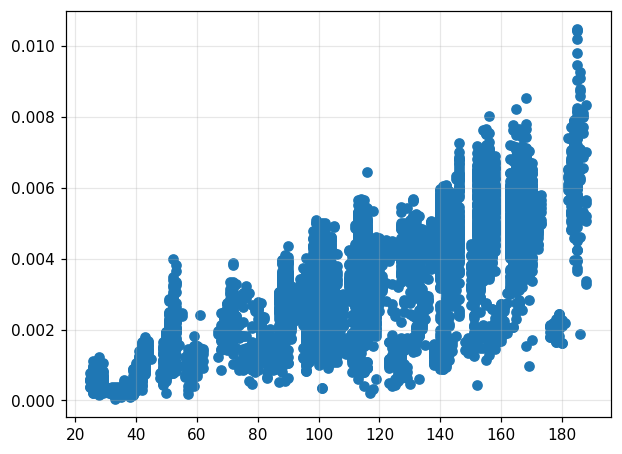

In [7]:
df_target = df.query("Run == 'g205z4'") #df_g39z4 g205z4
plt.scatter(df_target["Snapshot"],df_target["Z"])
len(df_target)

In [8]:
# HaloID is a per-snapshot index, not a fixed label, so "HaloID == 0" picks up a
# different halo whenever g205 is not the most massive group. Match the main
# branch from the tree instead, keep only snapshots where the host is the
# central of its group (the catalog stores centrals only), and drop
# unresolved clouds (< 30 elements).
tree_g205 = pd.read_csv(tz_gmc.host_tree_path("g205_z4"))
main_gid = dict(zip(tree_g205["snap"].astype(int), tree_g205["Group_GroupID"].astype(int)))
central = dict(zip(tree_g205["snap"].astype(int), tree_g205["Sub_SubhaloRankInGr"] == 0))

df_target = df_target[(df_target["HaloID"] == df_target["Snapshot"].map(main_gid))
                      & df_target["Snapshot"].map(central)
                      & (df_target["Number_of_Particles"] >= 30)]
df_target

,C_Fraction,C_Fraction_sfr,CenterPosition_0,CenterPosition_1,CenterPosition_2,EffectiveRadius,Fe_Fraction,Fe_Fraction_sfr,GasMass,H_Fraction,...,Run,SFR_inst,SFR_yso,Si_Fraction,Si_Fraction_sfr,Snapshot,StellarMass,VirialParameter,Z,Z_sfr
22846,0.000052,0.000049,0.176503,0.094493,-0.140167,0.031342,0.000028,0.000027,6.332619e+05,0.759946,...,g205z4,0.028924,9.850250,0.000022,0.000021,25,29550.7500,12.544486,0.000573,0.000554
22847,0.000052,0.000050,0.245519,0.309483,-0.273756,0.021461,0.000026,0.000025,5.926812e+05,0.759953,...,g205z4,0.028472,19.209979,0.000022,0.000021,25,57629.9375,5.219874,0.000592,0.000583
22850,0.000080,0.000067,0.013190,0.005155,0.001589,0.066816,0.000036,0.000030,3.022677e+06,0.759941,...,g205z4,0.431601,284.963667,0.000029,0.000024,26,854891.0000,17.599156,0.000833,0.000782
22851,0.000059,0.000055,0.140363,-0.059618,0.051951,0.050459,0.000027,0.000024,2.093149e+06,0.759959,...,g205z4,0.264651,104.914750,0.000023,0.000021,26,314744.2500,9.010038,0.000645,0.000640
22852,0.000088,0.000088,0.040646,-0.041581,0.260706,0.036060,0.000040,0.000040,9.939436e+05,0.759937,...,g205z4,0.086504,5.617250,0.000033,0.000033,26,16851.7500,3.082915,0.000926,0.000934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34946,0.000984,0.000881,-1.558052,-0.132754,-0.523150,0.024747,0.000326,0.000303,4.555646e+05,0.759567,...,g205z4,0.010995,0.000000,0.000219,0.000205,158,0.0000,9.949676,0.004955,0.004730
34947,0.001026,0.000813,-1.925177,-0.438573,-0.351041,0.022643,0.000328,0.000271,3.941194e+05,0.759512,...,g205z4,0.053989,12.317542,0.000220,0.000186,158,36952.6250,4.764850,0.005288,0.004834
34948,0.001220,NaN,-1.514287,-0.278039,0.499445,0.025830,0.000369,NaN,3.310916e+05,0.759474,...,g205z4,0.000000,22.149083,0.000246,NaN,158,66447.2500,18.414500,0.005955,NaN
34949,0.001144,NaN,-2.204168,-0.450865,-0.069576,0.018690,0.000381,NaN,3.804337e+05,0.759515,...,g205z4,0.000000,0.000000,0.000253,NaN,158,0.0000,3.385791,0.005545,NaN


clumps with SFR_inst = 0 (not shown): 938 of 4189


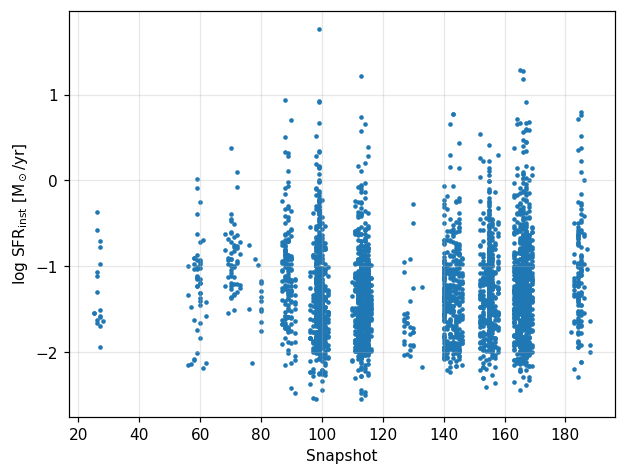

In [9]:
# log10(0) = -inf is dropped silently by matplotlib, so count the zeros explicitly
sf = df_target["SFR_inst"] > 0
plt.scatter(df_target.loc[sf, "Snapshot"], np.log10(df_target.loc[sf, "SFR_inst"]), s=4)
plt.xlabel("Snapshot")
plt.ylabel(r"log SFR$_{\rm inst}$ [M$_\odot$/yr]")
print("clumps with SFR_inst = 0 (not shown): %d of %d" % ((~sf).sum(), len(sf)))

clumps with StellarMass = 0 (not shown): 716 of 4189


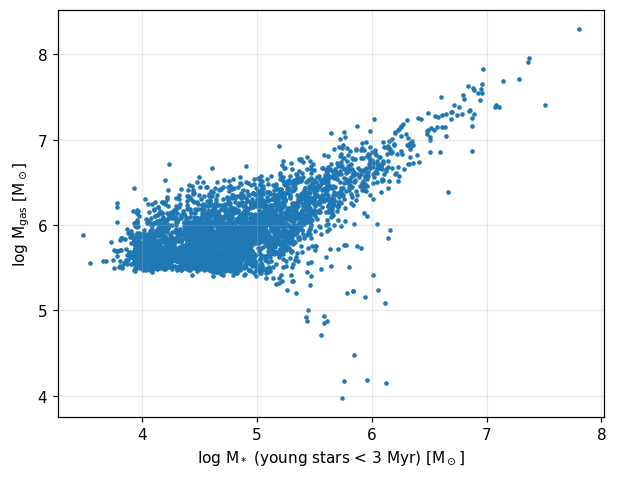

In [10]:
has_stars = df_target["StellarMass"] > 0
plt.scatter(np.log10(df_target.loc[has_stars, "StellarMass"]),
            np.log10(df_target.loc[has_stars, "GasMass"]), s=4)
plt.xlabel(r"log M$_*$ (young stars < 3 Myr) [M$_\odot$]")
plt.ylabel(r"log M$_{\rm gas}$ [M$_\odot$]")
print("clumps with StellarMass = 0 (not shown): %d of %d" % ((~has_stars).sum(), len(has_stars)))

---

## 1. Attaching the host galaxy

The catalog contains clouds only; there is no row for the host galaxy. So the host metallicity cannot come from the clumps: the mean over a galaxy's clumps makes ΔZ zero by construction, and the clump with the most stars is still just a clump. The host value has to come from the host's own subhalo in the main-progenitor tree.

Trees for all 14 fiducial runs (8 targets at 4×, 4 at 8×, 2 at 16×) were extracted on ORCD with `tz_tree_catalog.py` and live in `host_trees/` as `<target>_z<zoom>_host_halo.csv`. They are kept out of git and copied by hand. The cells below pick up every file there automatically (and a copy in the repo root, if any; `host_trees/` wins).

The tree offers several host apertures, and the answer depends on which one you compare to:

| key | tree field | what it measures |
|---|---|---|
| `all` | `SubhaloGasMetalFractions` | mass-weighted over all gas bound to the central subhalo, including the CGM |
| `halfrad` | `…HalfRad` | mass-weighted, gas within the stellar half-mass radius |
| `sf` | `…Sfr` | mass-weighted over star-forming cells only |
| `sfrw` | `…SfrWeighted` | SFR-weighted over all cells; the closest analogue of an emission-line host value |
| `sfrw_out` | derived below | SFR-weighted, after removing the resolved clumps' own contribution: the star-forming gas *outside* the clumps |


In [11]:
ZSUN = tz_gmc.ZSUN                       # 0.0127, used for clumps and host alike
A_O, A_H = 15.999, 1.008
GFM = {"H": 0, "He": 1, "C": 2, "N": 3, "O": 4, "Ne": 5, "Mg": 6, "Si": 7, "Fe": 8}
METALS = ["C", "N", "O", "Ne", "Mg", "Si", "Fe"]
APERTURES = {"all": "", "halfrad": "HalfRad", "sf": "Sfr", "sfrw": "SfrWeighted"}


def oh12(xo, xh):
    """12 + log(O/H) by number from O and H mass fractions; NaN where undefined."""
    xo, xh = np.asarray(xo, float), np.asarray(xh, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        v = 12 + np.log10((xo / A_O) / (xh / A_H))
    return np.where(np.isfinite(v), v, np.nan)


def load_host(path):
    """One row per snapshot: the main-branch host's metallicity in each aperture."""
    t = pd.read_csv(path)
    out = pd.DataFrame({"Snapshot": t["snap"].astype(int),
                        "GroupID": t["Group_GroupID"].astype(int),
                        "R200": t["phys_Group_Group_R_Crit200_kpc"],
                        "rhalf_star": t["phys_Sub_SubhaloHalfmassRadType_4_kpc"],
                        "rank": t["Sub_SubhaloRankInGr"].astype(int),
                        "host_SFR": t["Sub_SubhaloSFR"],
                        "group_SFR": t["Group_GroupSFR"],
                        "host_Mgas": t["phys_Sub_SubhaloMassType_0_Msun"],
                        "z_host": t["Redshift"]})
    for key, suf in APERTURES.items():
        x = {e: t[f"Sub_SubhaloGasMetalFractions{suf}_{i}"].to_numpy(float) for e, i in GFM.items()}
        xz = sum(x[e] for e in METALS)
        bad = xz <= 0                    # SFR-based apertures are 0 when the host has no SFR
        out[f"Z_{key}"] = np.where(bad, np.nan, xz / ZSUN)
        out[f"OH_{key}"] = np.where(bad, np.nan, oh12(x["O"], x["H"]))
        if key == "sfrw":                # kept to subtract the clumps' share later
            out["XO_sfrw"], out["XH_sfrw"], out["XZ_sfrw"] = x["O"], x["H"], xz
    return out


hosts = {}
# repo root first, host_trees/ last, so host_trees/ wins if a run is in both
for path in sorted(glob.glob("*_host_halo.csv")) + sorted(glob.glob("host_trees/*_host_halo.csv")):
    target, zoom = os.path.basename(path).replace("_host_halo.csv", "").split("_")
    hosts[target + zoom] = load_host(path)
print("runs with a host tree (%d): %s" % (len(hosts), ", ".join(hosts)))

runs with a host tree (14): g10304z4, g10304z8, g1163z4, g137030z16, g205z4, g33206z4, g33206z8, g37591z4, g37591z8, g39z4, g500531z16, g5760z4, g5760z8, g578z4


## 1b. Does the catalog's `HaloID` point to the same galaxy as the tree?

Everything below assumes that clouds with `HaloID == Group_GroupID` belong to the host described by the tree. Both numbers are documented as the index of a FoF group in that snapshot's `fof_subhalo_tab` (catalog readme; `tz_tree_catalog.py`), and the paper's sample is the central galaxies, i.e. the main SUBFIND-HBT subhalo of each group (Wang et al. 2025, §2.2). That does not prove the catalog was built from the same group files as the tree, so these tests check it in the data. They use every cloud, including unresolved ones, which is the strictest version.

1. **Conservation.** `SFR_inst` and `GasMass` are sums over gas cells, so a galaxy's clouds can never carry more SFR or gas than the galaxy. Clouds of a *different* galaxy have no such limit.
2. **Reshuffled snapshots.** Where the host is not group 0, the tree's `GroupID` and `HaloID == 0` point to different groups. Only the right one can satisfy test 1.
3. **Time tracking.** The host SFR is bursty; its own clouds' summed SFR should follow it snapshot by snapshot.
4. **Satellite snapshots.** Where the host is not the central of its group (`rank != 0`), the catalog should hold no clouds for it.
5. **Coverage.** Which snapshots have clouds at all, for any halo in the run, and for the host.

**Result for the 14 trees (2026-11-13).** All 12 runs at 4× and 8× pass. In both 16× runs the catalog's clouds sit under one other `HaloID` (2 for g137030, 1 for g500531) at every snapshot, while the target is group 0 with essentially no star formation. The paper catalogued bursts of *any* central, and at 16× those were neighbours. So the 16× runs have no target clouds; they drop out of every host comparison automatically and only enter host-independent statistics. The "others exceed host" evidence is in the table above; it is not a requirement (a run whose other haloes are all small has none).

Clouds can include star-forming gas from other galaxies in the same FoF group. At g578 snapshot 176, clouds beyond 0.15 R200c carry 9.3 of 10.2 Msun/yr. At 8×, 27–40% of matched clouds lie beyond 0.15 R200c (5–13% at 4×).


In [12]:
allclouds = tz_gmc.load(variant="fiducial")      # every cloud, unresolved included


def rho(a, b):
    """Spearman rho, NaN when there are too few points to mean anything."""
    a, b = np.asarray(a, float), np.asarray(b, float)
    return spearmanr(a, b)[0] if len(a) >= 3 else np.nan


def host_match_table(run, host):
    """One row per (snapshot, HaloID) with the clouds' totals relative to the tree host."""
    h = host.set_index("Snapshot")
    cl = allclouds[allclouds["Run"] == run]
    per = (cl.groupby(["Snapshot", "HaloID"])
             .agg(N=("sfr_inst", "size"), SFR=("sfr_inst", "sum"), Mgas=("M_gas", "sum"), Z=("Z_Zsun", "median"))
             .reset_index())
    s = per["Snapshot"]
    per["tree_gid"] = s.map(h["GroupID"])
    per["rank"] = s.map(h["rank"])
    per["matched"] = per["HaloID"] == per["tree_gid"]
    with np.errstate(divide="ignore", invalid="ignore"):
        per["r_SFR"] = (per["SFR"] / s.map(h["host_SFR"])).replace(np.inf, np.nan)
        per["r_SFR_group"] = (per["SFR"] / s.map(h["group_SFR"])).replace(np.inf, np.nan)
        per["r_Mgas"] = per["Mgas"] / s.map(h["host_Mgas"])
        per["r_Z"] = per["Z"] / s.map(h["Z_all"])
    return per


summary, tables = [], {}
for run, host in hosts.items():
    per = host_match_table(run, host)
    tables[run] = per
    h = host.set_index("Snapshot")
    yes = per[per["matched"] & (per["rank"] == 0)]
    no = per[~per["matched"]]
    reshuffled = per["Snapshot"].isin(h.index[h["GroupID"] != 0])
    m_rs, z_rs = per[reshuffled & per["matched"]], per[reshuffled & ~per["matched"] & (per["HaloID"] == 0)]
    tr_yes, tr_no = yes[(yes["SFR"] > 0) & yes["r_SFR"].notna()], no[(no["SFR"] > 0) & no["r_SFR"].notna()]
    sat = per[per["matched"] & (per["rank"] != 0)]
    summary.append({
        "run": run,
        # test 1
        "matched pairs": len(yes),
        "matched: max sum Mgas / host": yes["r_Mgas"].max(),
        "matched: pairs SFR > host": int((yes["r_SFR"] > 1.0001).sum()),
        "matched: max SFR / host": yes["r_SFR"].max(),
        "matched: pairs SFR > group": int((yes["r_SFR_group"] > 1.0001).sum()),
        "other: pairs SFR > host": int((no["r_SFR"] > 1.0001).sum()),
        "other: max SFR / host": no["r_SFR"].max(),
        # test 2
        "reshuffled: matched max SFR / host": m_rs["r_SFR"].max(),
        "reshuffled: HaloID 0 max SFR / host": z_rs["r_SFR"].max(),
        "reshuffled: matched median Z ratio": m_rs["r_Z"].median(),
        # test 3
        "tracking rho, matched": rho(tr_yes["SFR"], tr_yes["Snapshot"].map(h["host_SFR"])),
        "tracking rho, other": rho(tr_no["SFR"], tr_no["Snapshot"].map(h["host_SFR"])),
        # test 4
        "satellite snapshots with host clouds": int(sat["Snapshot"].nunique()),
    })

pd.set_option("display.max_colwidth", 60)
pd.DataFrame(summary).set_index("run").T.round(3)

run,g10304z4,g10304z8,g1163z4,g137030z16,g205z4,g33206z4,g33206z8,g37591z4,g37591z8,g39z4,g500531z16,g5760z4,g5760z8,g578z4
matched pairs,37.000,54.000,59.000,0.000,79.000,24.000,34.000,13.000,40.000,48.000,0.0,44.000,73.000,47.000
matched: max sum Mgas / host,0.015,0.015,0.010,NaN,0.016,0.003,0.071,0.005,0.006,0.048,NaN,0.015,0.017,0.019
matched: pairs SFR > host,0.000,3.000,1.000,0.000,2.000,0.000,4.000,0.000,0.000,1.000,0.0,0.000,0.000,1.000
matched: max SFR / host,0.890,1.034,2.632,NaN,1.100,0.926,1.457,0.575,1.000,1.002,NaN,0.932,1.000,2.758
matched: pairs SFR > group,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.0,0.000,0.000,0.000
other: pairs SFR > host,27.000,67.000,59.000,2.000,35.000,0.000,10.000,1.000,1.000,0.000,0.0,1.000,12.000,118.000
other: max SFR / host,158.537,121.782,99.557,3.244,47.293,0.000,30.641,2.953,3.122,NaN,0.0,2.652,7.983,89.199
reshuffled: matched max SFR / host,0.890,1.034,0.772,NaN,0.823,NaN,NaN,NaN,NaN,1.002,NaN,NaN,NaN,0.852
reshuffled: HaloID 0 max SFR / host,158.537,40.520,15.919,NaN,47.293,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.199
reshuffled: matched median Z ratio,1.054,1.076,1.021,NaN,1.023,NaN,NaN,NaN,NaN,0.982,NaN,NaN,NaN,1.008


In [13]:
# Pass/fail per run. "n/a" where a test has nothing to act on: no other haloes
# with clouds, no reshuffled snapshots with host clouds, or fewer than 10
# snapshots to correlate. A violation of the host limit that stays within the
# group limit means the clouds include some group gas not bound to the
# central; it is listed, not failed.
def state(ok, applicable=True):
    if not applicable:
        return "n/a"
    return "PASS" if ok else "CHECK"


rows = []
for row in summary:
    run = row["run"]          # separate lines: a tuple assignment would read the previous run
    per = tables[run]
    h = hosts[run].set_index("Snapshot")
    yes = per[per["matched"] & (per["rank"] == 0)]
    no = per[~per["matched"]]
    reshuffled = per["Snapshot"].isin(h.index[h["GroupID"] != 0])
    n_track = int(((yes["SFR"] > 0) & yes["r_SFR"].notna()).sum())
    over = yes[yes["r_SFR"] > 1.0001]
    rows.append({
        "run": run,
        "host snapshots": int(yes["Snapshot"].nunique()),
        "1 within host/group": state(row["matched: pairs SFR > group"] == 0
                                     and row["matched: max sum Mgas / host"] <= 1, len(yes) > 0),
        "2 reshuffled": state(not (per.loc[reshuffled & per["matched"], "r_SFR_group"].max() > 1.0001),
                              bool((reshuffled & per["matched"]).any())),
        "3 tracking": state(row["tracking rho, matched"] > 0.8 and not (row["tracking rho, other"] >= 0.5),
                            n_track >= 10),
        "4 no satellite clouds": state(row["satellite snapshots with host clouds"] == 0),
        "SFR > subhalo, < group at snaps": ", ".join(str(s) for s in over["Snapshot"]) or "-",
    })
verdicts = pd.DataFrame(rows).set_index("run")
verdicts

,host snapshots,1 within host/group,2 reshuffled,3 tracking,4 no satellite clouds,"SFR > subhalo, < group at snaps"
run,,,,,,
g10304z4,37,PASS,PASS,PASS,PASS,-
g10304z8,54,PASS,PASS,PASS,PASS,"185, 187, 188"
g1163z4,59,PASS,PASS,PASS,PASS,51
g137030z16,0,n/a,n/a,n/a,PASS,-
g205z4,79,PASS,PASS,PASS,PASS,"98, 99"
g33206z4,24,PASS,n/a,n/a,PASS,-
g33206z8,34,PASS,n/a,PASS,PASS,"73, 74, 183, 185"
g37591z4,13,PASS,n/a,n/a,PASS,-
g37591z8,40,PASS,n/a,PASS,PASS,-


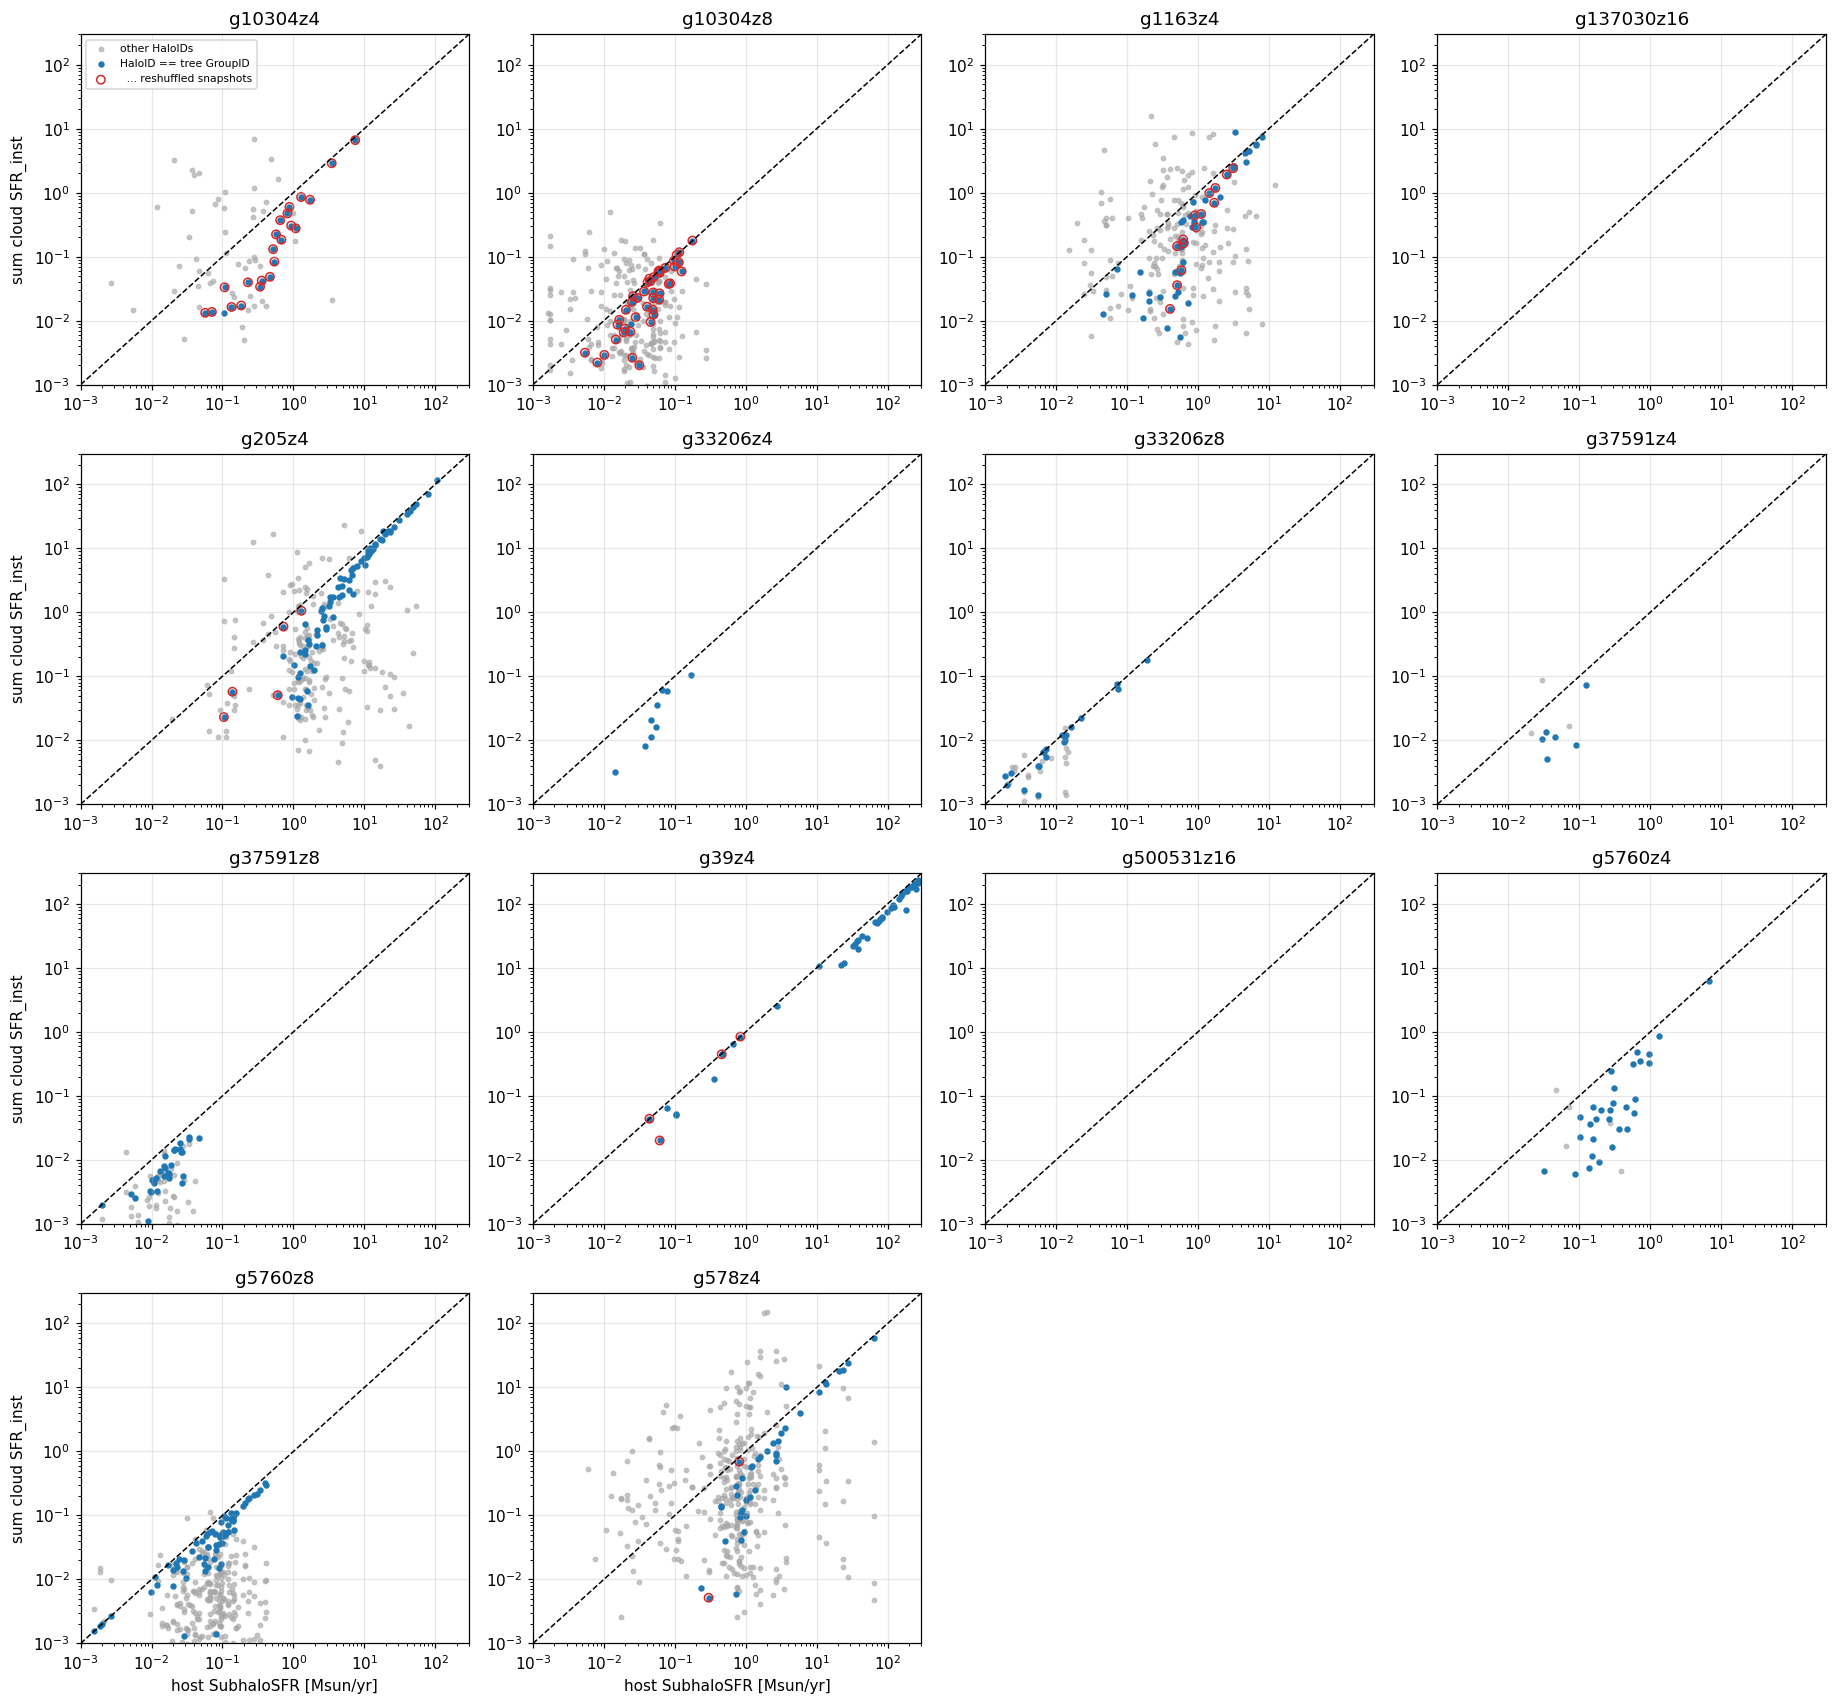

In [14]:
# Test 1-3 in one picture: clouds' summed SFR against the host's SFR, per (snapshot, HaloID).
ncol = 4
nrow = int(np.ceil(len(tables) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4.2 * ncol, 3.9 * nrow), squeeze=False)
lim = [1e-3, 3e2]
for ax, (run, per) in zip(axes.flat, tables.items()):
    h = hosts[run].set_index("Snapshot")
    p = per[per["SFR"] > 0].copy()
    p["host_SFR"] = p["Snapshot"].map(h["host_SFR"])
    p = p[p["host_SFR"] > 0]
    other = p[~p["matched"]]
    good = p[p["matched"] & (p["rank"] == 0)]
    rs = good["Snapshot"].isin(h.index[h["GroupID"] != 0])
    ax.scatter(other["host_SFR"], other["SFR"], s=8, c="0.65", alpha=0.6, label="other HaloIDs")
    ax.scatter(good["host_SFR"], good["SFR"], s=10, c="C0", label="HaloID == tree GroupID")
    ax.scatter(good.loc[rs, "host_SFR"], good.loc[rs, "SFR"], s=30, facecolors="none",
               edgecolors="C3", label="  ... reshuffled snapshots")
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=run)
for ax in axes.flat[len(tables):]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("sum cloud SFR_inst")
for ax in axes[-1, :]:
    ax.set_xlabel("host SubhaloSFR [Msun/yr]")
axes[0, 0].legend(fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

In [15]:
# Test 5: which snapshots have clouds at all?
rows = []
for run, host in hosts.items():
    h = host.set_index("Snapshot")
    per = tables[run]
    snaps_any = set(allclouds.loc[allclouds["Run"] == run, "Snapshot"])
    snaps_host = set(per.loc[per["matched"] & (per["rank"] == 0), "Snapshot"])
    missing = sorted(set(h.index) - snaps_any)
    busy = [s for s in missing if h.loc[s, "host_SFR"] > 1]
    proc = h.loc[sorted(snaps_any & set(h.index))]
    has = proc.index.isin(snaps_host)
    rows.append({"run": run, "tree snapshots": len(h),
                 "with any clouds": len(snaps_any), "with host clouds": len(snaps_host),
                 "unprocessed with host SFR > 1": len(busy),
                 "host SFR median, with host clouds": proc.loc[has, "host_SFR"].median(),
                 "host SFR median, without": proc.loc[~has, "host_SFR"].median()})
pd.DataFrame(rows).set_index("run").round(2)

,tree snapshots,with any clouds,with host clouds,unprocessed with host SFR > 1,"host SFR median, with host clouds","host SFR median, without"
run,,,,,,
g10304z4,189,96,37,1,0.25,0.11
g10304z8,189,150,54,0,0.04,0.02
g1163z4,189,138,59,0,0.65,0.26
g137030z16,189,7,0,0,NaN,0.00
g205z4,189,155,79,6,4.30,1.37
g33206z4,188,26,24,0,0.03,0.04
g33206z8,189,63,34,0,0.01,0.00
g37591z4,189,14,13,0,0.03,0.03
g37591z8,189,75,40,0,0.01,0.02


## 2. Clump sample

Fiducial clouds at all three resolutions, resolved (≥ 30 elements), in the main-branch host group of each run that has a tree, at snapshots where the host is the central of its group (section 1b), and **inside the galaxy**: distance < R_gal = min(2 r½,\*, 0.15 R200c), the definition of the clumpiness paper (Sec. 2.2), with 0.15 R200c while the host has no stars yet. Clouds beyond R_gal belong to the outskirts or to other galaxies in the same FoF group (27–40% of clouds at 8×, 5–13% at 4×). `clumps` is this default sample; `clumps_all` keeps every matched cloud for comparison.

Resolution sets the smallest cloud (median R_eff ≈ 30 / 22 / 13 pc at 4× / 8× / 16×), so results below are reported **per resolution** and never pooled across resolutions. Figures that need a single sample use 4×, which has 8 of the 14 runs.

Two clump metallicities:

- `Z_Zsun`, `OH`: mass-weighted over the cloud's gas (every resolved clump has one)
- `Z_sfr`, `OH_sfr`: SFR-weighted, defined only for star-forming clumps. This is the analogue of an emission-line clump measurement.


In [16]:
cat = tz_gmc.load(variant="fiducial", resolved_only=True)    # all resolutions; "res" says which
cat["OH"] = oh12(cat["O_Fraction"], cat["H_Fraction"])
cat["OH_sfr"] = oh12(cat["O_Fraction_sfr"], cat["H_Fraction_sfr"])
cat["Z_sfr_Zsun"] = cat["Z_sfr"] / ZSUN

parts = []
for run, host in hosts.items():
    c = cat[cat["Run"] == run].merge(host, on="Snapshot")
    parts.append(c[(c["HaloID"] == c["GroupID"]) & (c["rank"] == 0)])   # main branch, host is central
clumps_all = pd.concat(parts, ignore_index=True)
clumps_all["x"] = clumps_all["d_center_kpc"] / clumps_all["R200"]
clumps_all["star_forming"] = clumps_all["sfr_inst"] > 0

# Galaxy boundary (clumpiness paper, Sec. 2.2): R_gal = min(2 r_1/2,*, 0.15 R200c),
# falling back to 0.15 R200c while the host has no stars yet.
cap = 0.15 * clumps_all["R200"]
clumps_all["R_gal"] = np.where(clumps_all["rhalf_star"] > 0, np.minimum(2 * clumps_all["rhalf_star"], cap), cap)
clumps_all["in_gal"] = clumps_all["d_center_kpc"] < clumps_all["R_gal"]
clumps = clumps_all[clumps_all["in_gal"]].copy()          # default sample from here on

print("checks: Z range %.3f - %.3f Zsun, distance %.2f - %.1f kpc, 12+log(O/H) %.2f - %.2f\n"
      % (clumps_all["Z_Zsun"].min(), clumps_all["Z_Zsun"].max(), clumps_all["d_center_kpc"].min(),
         clumps_all["d_center_kpc"].max(), clumps_all["OH"].min(), clumps_all["OH"].max()))
g_all = clumps_all.groupby(["res", "Run"])
g_in = clumps.groupby(["res", "Run"])
pd.DataFrame({
    "matched clouds": g_all.size(),
    "inside R_gal": g_in.size(),
    "kept %": 100 * g_in.size() / g_all.size(),
    "SFR kept %": 100 * g_in["sfr_inst"].sum() / g_all["sfr_inst"].sum(),
    "star-forming inside": g_in["star_forming"].sum(),
    "snapshots": g_in["Snapshot"].nunique(),
    "z_max": g_in["z"].max(), "z_min": g_in["z"].min()}).round(1)

checks: Z range 0.000 - 1.591 Zsun, distance 0.00 - 51.9 kpc, 12+log(O/H) 4.31 - 8.93



matched clouds  inside R_gal  kept %  SFR kept %  \
res Run                                                          
4   g10304z4             332           307    92.5        97.7   
    g1163z4              633           599    94.6        98.6   
    g205z4              4189          3844    91.8        97.9   
    g33206z4              32            28    87.5        84.5   
    g37591z4              18            16    88.9       100.0   
    g39z4              10825         10316    95.3        99.2   
    g5760z4              334           309    92.5        97.8   
    g578z4              2224          1936    87.1        89.0   
8   g10304z8            3799          2424    63.8        62.9   
    g33206z8             460           296    64.3        79.9   
    g37591z8             688           501    72.8        67.3   
    g5760z8             4752          2855    60.1        67.3   

              star-forming inside  snapshots  z_max  z_min  
res Run                                                     
4   g10304z4                  171         23    5.7    3.4  
    g1163z4                   449         48    9.6    3.1  
    g205z4                   3026         71    9.6    3.0  
    g33206z4                    8         14    5.7    3.4  
    g37591z4                    2          7    3.4    3.3  
    g39z4                    9568         41   14.8    3.0  
    g5760z4                   141         36    5.5    3.1  
    g578z4                   1302         44    7.5    3.1  
8   g10304z8                  242         50    5.2    3.0  
    g33206z8                   38         25    6.8    3.0  
    g37591z8                   65         39    4.8    3.0  
    g5760z8                   702         68    7.9    3.2

## 3. Clump vs host, one value per snapshot

Clumps in the same snapshot share one gas reservoir, so they are not independent measurements. Each snapshot is summarised by its median clump, and scatter is quoted across snapshots.

The `sfrw_out` host removes the resolved clumps from the host's SFR-weighted average:

X_out = (SFR_host · X_host,sfrw − Σ SFR_clump · X_clump,sfr) / (SFR_host − Σ SFR_clump).

This assumes the clumps' cells are part of the central subhalo. It is left undefined where the resolved clumps carry more than 90% of the host SFR, since the remainder is then too small to measure.

`build_snaps()` holds every analysis choice as a parameter, so section 9 can rerun the whole comparison under alternatives:

- `oh_col`: the clump O/H, SFR-weighted (`OH_sfr`, default) or mass-weighted (`OH`)
- `sf_col`: which clumps count as star-forming (default `SFR_inst > 0`)
- `stat`: median clump (default) or all clumps combined, SFR-weighted (`"sfr_agg"`)
- `fmax`: largest clump share of the host SFR for which the "outside clumps" host is defined (default 0.9)
- `min_sf`: fewest star-forming clumps a snapshot needs (default 1)

The subtraction always removes every clump with instantaneous star formation, whatever `sf_col` says, because those are what the host's SFR-weighted value contains.


In [17]:
host_all = pd.concat([h.assign(Run=r) for r, h in hosts.items()]).set_index(["Run", "Snapshot"])


def build_snaps(cl, oh_col="OH_sfr", sf_col="star_forming", stat="median", fmax=0.9, min_sf=1):
    """One row per (run, snapshot): clump summary, host apertures and the offsets."""

    def per_snapshot(c):
        inst = c["sfr_inst"] > 0                     # what the host's SFR weighting contains
        w = c.loc[inst, "sfr_inst"]
        sel = c[sf_col]                              # which clumps represent "star-forming clumps"
        zcol = "Z_sfr_Zsun" if oh_col == "OH_sfr" else "Z_Zsun"
        xo, xh, xz = ((w * c.loc[inst, "O_Fraction_sfr"]).sum(), (w * c.loc[inst, "H_Fraction_sfr"]).sum(),
                      (w * c.loc[inst, "Z_sfr"]).sum())
        if stat == "sfr_agg":                        # all clumps combined, as one emission-weighted region
            oh_sel = float(oh12(xo, xh)) if w.sum() > 0 else np.nan
            z_sel = xz / w.sum() / ZSUN if w.sum() > 0 else np.nan
        else:
            oh_sel, z_sel = c.loc[sel, oh_col].median(), c.loc[sel, zcol].median()
        return pd.Series({
            "z": c["z"].iloc[0], "res": int(c["res"].iloc[0]), "N": len(c), "N_sf": int(sel.sum()),
            "Z_clump": c["Z_Zsun"].median(), "OH_clump": c["OH"].median(),
            "Z_clump_sfr": z_sel, "OH_clump_sfr": oh_sel,
            "SFR_clumps": w.sum(), "XO_cl": xo, "XH_cl": xh, "XZ_cl": xz})

    sn = cl.groupby(["Run", "Snapshot"]).apply(per_snapshot, include_groups=False).join(host_all)

    # host star formation outside the resolved clumps
    sn["f_clump_SFR"] = sn["SFR_clumps"] / sn["host_SFR"]
    ok = (sn["host_SFR"] > 0) & (sn["f_clump_SFR"] < fmax)
    rest = sn["host_SFR"] - sn["SFR_clumps"]
    xo = (sn["host_SFR"] * sn["XO_sfrw"] - sn["XO_cl"]) / rest
    xh = (sn["host_SFR"] * sn["XH_sfrw"] - sn["XH_cl"]) / rest
    xz = (sn["host_SFR"] * sn["XZ_sfrw"] - sn["XZ_cl"]) / rest
    sn["OH_sfrw_out"] = np.where(ok, oh12(xo, xh), np.nan)
    sn["Z_sfrw_out"] = np.where(ok & (xz > 0), xz / ZSUN, np.nan)

    # offsets in dex: mass-weighted clumps against the mass-weighted apertures,
    # star-forming clumps against the SFR-based ones
    for key in ["all", "halfrad", "sf"]:
        sn[f"dlogZ_{key}"] = np.log10(sn["Z_clump"] / sn[f"Z_{key}"])
        sn[f"dOH_{key}"] = sn["OH_clump"] - sn[f"OH_{key}"]
    few = sn["N_sf"] < min_sf
    for key in ["sfrw", "sfrw_out"]:
        sn[f"dlogZ_{key}"] = np.where(few, np.nan, np.log10(sn["Z_clump_sfr"] / sn[f"Z_{key}"]))
        sn[f"dOH_{key}"] = np.where(few, np.nan, sn["OH_clump_sfr"] - sn[f"OH_{key}"])
    return sn


snaps = build_snaps(clumps)
print("snapshots: %d;  with a defined 'outside clumps' host: %d"
      % (len(snaps), snaps["OH_sfrw_out"].notna().sum()))
print("share of host SFR in resolved clumps inside R_gal: median %.2f (16-84%%: %.2f - %.2f)"
      % tuple(snaps["f_clump_SFR"].quantile([0.5, 0.16, 0.84])))

snapshots: 466;  with a defined 'outside clumps' host: 445
share of host SFR in resolved clumps inside R_gal: median 0.32 (16-84%: 0.00 - 0.76)


In [18]:
HOSTS = ["all", "halfrad", "sf", "sfrw", "sfrw_out"]


def summarise(s):
    s = s.dropna()
    if len(s) == 0:
        return "-"
    return "%+.3f [%+.3f, %+.3f] n=%d" % (s.median(), s.quantile(0.16), s.quantile(0.84), len(s))


print("Delta 12+log(O/H) = clump - host [dex]; median [16th, 84th] over snapshots, per resolution\n")
by_res = pd.DataFrame({key: snaps.groupby("res")[f"dOH_{key}"].apply(summarise) for key in HOSTS})
display(by_res)

print("\nheadline (SF clumps vs host SF gas outside clumps), per run:")
per_run = snaps.groupby(["res", "Run"]).agg(
    snapshots=("dOH_sfrw_out", "count"), median=("dOH_sfrw_out", "median"),
    p16=("dOH_sfrw_out", lambda s: s.quantile(0.16)), p84=("dOH_sfrw_out", lambda s: s.quantile(0.84)))
display(per_run.round(3))

zbins = [3, 3.5, 4, 5, 6, 8, 10]
s4 = snaps[snaps["res"] == 4]
table = s4.groupby(pd.cut(s4["z"], zbins), observed=True)[[f"dOH_{k}" for k in HOSTS]].median()
table.insert(0, "snapshots", s4.groupby(pd.cut(s4["z"], zbins), observed=True).size())
print("\n4x, by redshift (median over snapshots):")
table.round(3)

Delta 12+log(O/H) = clump - host [dex]; median [16th, 84th] over snapshots, per resolution



,all,halfrad,sf,sfrw,sfrw_out
res,,,,,
4.0,"+0.010 [-0.051, +0.059] n=284","-0.014 [-0.074, +0.020] n=283","+0.056 [-0.005, +0.123] n=284","+0.039 [-0.008, +0.101] n=245","+0.026 [-0.021, +0.088] n=236"
8.0,"+0.017 [-0.038, +0.077] n=182","-0.011 [-0.063, +0.044] n=178","+0.027 [-0.048, +0.099] n=181","+0.031 [-0.031, +0.091] n=137","+0.077 [-0.050, +0.194] n=126"



headline (SF clumps vs host SF gas outside clumps), per run:


snapshots  median    p16    p84
res Run                                      
4.0 g10304z4         17   0.012 -0.023  0.051
    g1163z4          43   0.036 -0.060  0.102
    g205z4           68   0.026 -0.013  0.070
    g33206z4          6  -0.046 -0.068  0.019
    g37591z4          2   0.024  0.011  0.036
    g39z4            37   0.018 -0.016  0.082
    g5760z4          25   0.061  0.011  0.111
    g578z4           38   0.044 -0.001  0.102
8.0 g10304z8         34   0.087 -0.063  0.194
    g33206z8          9  -0.011 -0.093  0.094
    g37591z8         26  -0.001 -0.082  0.083
    g5760z8          57   0.110  0.015  0.236


4x, by redshift (median over snapshots):


,snapshots,dOH_all,dOH_halfrad,dOH_sf,dOH_sfrw,dOH_sfrw_out
z,,,,,,
"(3.0, 3.5]",95,0.003,-0.019,0.080,0.056,0.025
"(3.5, 4.0]",65,0.016,-0.012,0.068,0.041,0.024
"(4.0, 5.0]",59,0.026,-0.000,0.036,0.027,0.030
"(5.0, 6.0]",36,-0.003,-0.014,0.023,0.019,0.020
"(6.0, 8.0]",15,-0.050,-0.072,-0.041,-0.037,-0.048
"(8.0, 10.0]",7,0.050,0.004,0.065,0.090,0.140


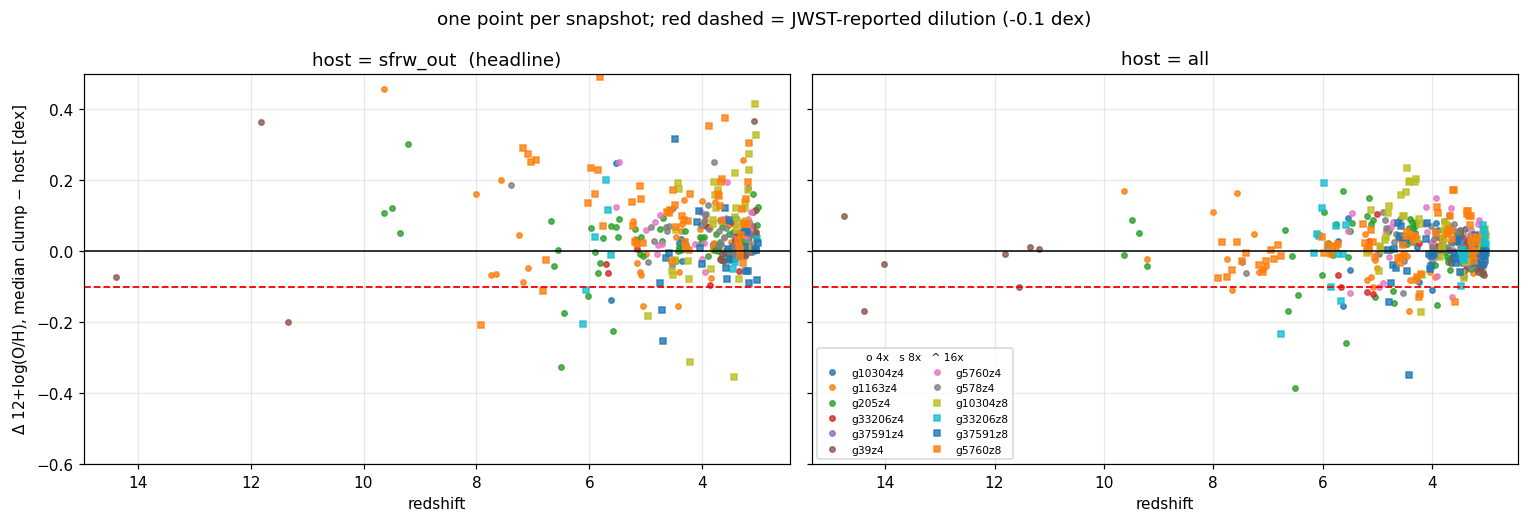

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, key in zip(axes, ["sfrw_out", "all"]):
    for (res, run), s in snaps.groupby(["res", "Run"]):
        ax.plot(s["z"], s[f"dOH_{key}"], {4: "o", 8: "s", 16: "^"}[res], ms=3.5, alpha=0.8, label=run)
    ax.axhline(0, color="k", lw=1)
    ax.axhline(-0.1, color="r", ls="--", lw=1.2)
    ax.invert_xaxis()
    ax.set_xlabel("redshift")
    ax.set_title(f"host = {key}" + ("  (headline)" if key == "sfrw_out" else ""))
axes[0].set_ylabel(r"$\Delta$ 12+log(O/H), median clump $-$ host [dex]")
axes[1].legend(fontsize=7, ncol=2, loc="lower left", title="o 4x   s 8x   ^ 16x", title_fontsize=7)
axes[0].set_ylim(-0.6, 0.5)
plt.suptitle("one point per snapshot; red dashed = JWST-reported dilution (-0.1 dex)")
plt.tight_layout()
plt.show()

## 4. Clump vs host metallicity plane

4× runs only (8 targets). Same axes as the earlier Figure 6 attempt (host log Z on x, clump log Z on y), but with the host taken from the tree at the clump's own snapshot, and colour showing redshift. Left: mass-weighted clumps against all host gas. Right: SFR-weighted star-forming clumps against the host's star-forming gas outside the clumps.


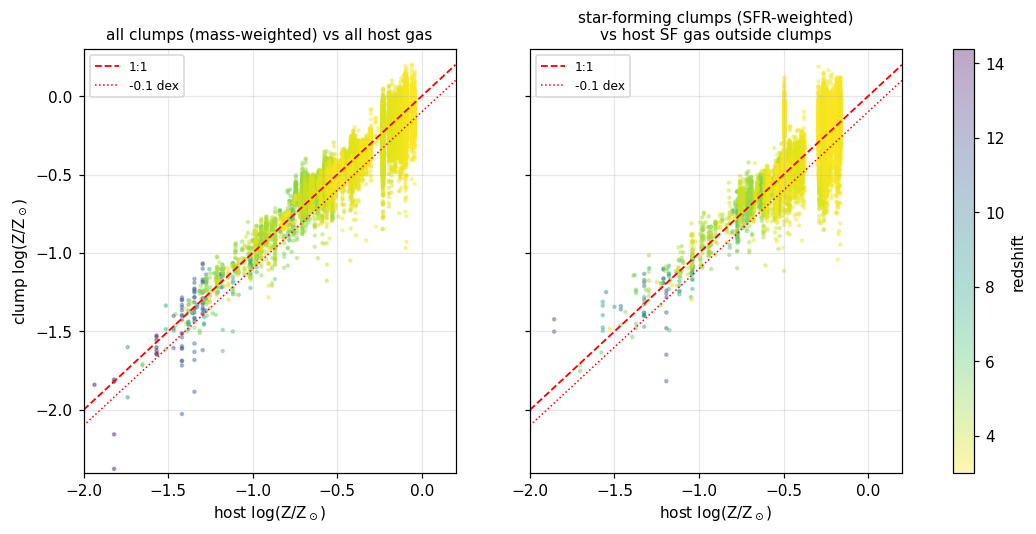

In [20]:
pc = clumps[clumps["res"] == 4].join(snaps[["Z_sfrw_out"]], on=["Run", "Snapshot"])
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
lims = [-2.0, 0.2]
panels = [("Z_all", "Z_Zsun", "all clumps (mass-weighted) vs all host gas", pc),
          ("Z_sfrw_out", "Z_sfr_Zsun", "star-forming clumps (SFR-weighted)\nvs host SF gas outside clumps",
           pc[pc["star_forming"]])]
for ax, (xcol, ycol, title, d) in zip(axes, panels):
    d = d[(d[xcol] > 0) & (d[ycol] > 0)]
    sc = ax.scatter(np.log10(d[xcol]), np.log10(d[ycol]), c=d["z"], s=4, alpha=0.35, cmap="viridis_r")
    ax.plot(lims, lims, "r--", lw=1.2, label="1:1")
    ax.plot(lims, np.array(lims) - 0.1, "r:", lw=1, label="-0.1 dex")
    ax.set_xlim(lims); ax.set_ylim(-2.4, 0.3)
    ax.set_xlabel(r"host log(Z/Z$_\odot$)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_ylabel(r"clump log(Z/Z$_\odot$)")
fig.colorbar(sc, ax=axes, label="redshift")
plt.show()

## 5. Which clumps are diluted?

Two different questions that the earlier version mixed up:

- **Scatter among clumps**: how far a clump sits from the *other clumps* of the same galaxy at the same time. This says nothing about the host.
- **Dilution relative to the host**: Δ12+log(O/H) against the host's star-forming gas outside the clumps, using the same −0.1 dex threshold as the observations. Only star-forming clumps have an emission-line-like O/H, so only they enter.


In [21]:
clumps["dOH_vs_snapshot"] = clumps["OH"] - clumps.groupby(["Run", "Snapshot"])["OH"].transform("median")
multi = clumps.groupby(["Run", "Snapshot"])["OH"].transform("size") >= 5

sfc = clumps[clumps["star_forming"]].join(snaps[["OH_sfrw_out"]], on=["Run", "Snapshot"])
sfc = sfc[sfc["OH_sfrw_out"].notna()].copy()
sfc["dOH_host"] = sfc["OH_sfr"] - sfc["OH_sfrw_out"]
sfc["diluted"] = sfc["dOH_host"] <= -0.1

rows = []
for res in sorted(clumps["res"].unique()):
    s = clumps.loc[multi & (clumps["res"] == res), "dOH_vs_snapshot"]
    f = sfc[sfc["res"] == res]
    fd = f.groupby(["Run", "Snapshot"])["diluted"].mean()      # per snapshot, so busy snapshots cannot dominate
    rows.append({"resolution": f"{res}x",
                 "scatter among clumps, 16th": s.quantile(0.16), "84th": s.quantile(0.84),
                 "% > 0.1 dex below snapshot median": 100 * (s < -0.1).mean(),
                 "SF clumps vs host": len(f),
                 "median offset vs host": f["dOH_host"].median(),
                 "% diluted (<= -0.1 dex)": 100 * f["diluted"].mean(),
                 "% diluted, per-snapshot median": 100 * fd.median()})
print("scatter among clumps of one snapshot (>= 5 clumps) and dilution relative to the host's SF gas outside clumps")
pd.DataFrame(rows).set_index("resolution").round(3)

scatter among clumps of one snapshot (>= 5 clumps) and dilution relative to the host's SF gas outside clumps


,"scatter among clumps, 16th",84th,% > 0.1 dex below snapshot median,SF clumps vs host,median offset vs host,% diluted (<= -0.1 dex),"% diluted, per-snapshot median"
resolution,,,,,,,
4x,-0.090,0.071,13.952,14259,0.018,18.585,0.0
8x,-0.086,0.065,13.457,973,0.075,7.503,0.0


4x: median properties, diluted vs not (star-forming clumps)


diluted,False,True
M_gas [Msun],743104.438,1027967.688
SFR_inst [Msun/yr],0.055,0.118
virial parameter,10.466,12.013
Sigma_gas [Msun/pc^2],249.898,283.420
d / R200c,0.040,0.044
R_eff [pc],31.181,34.500


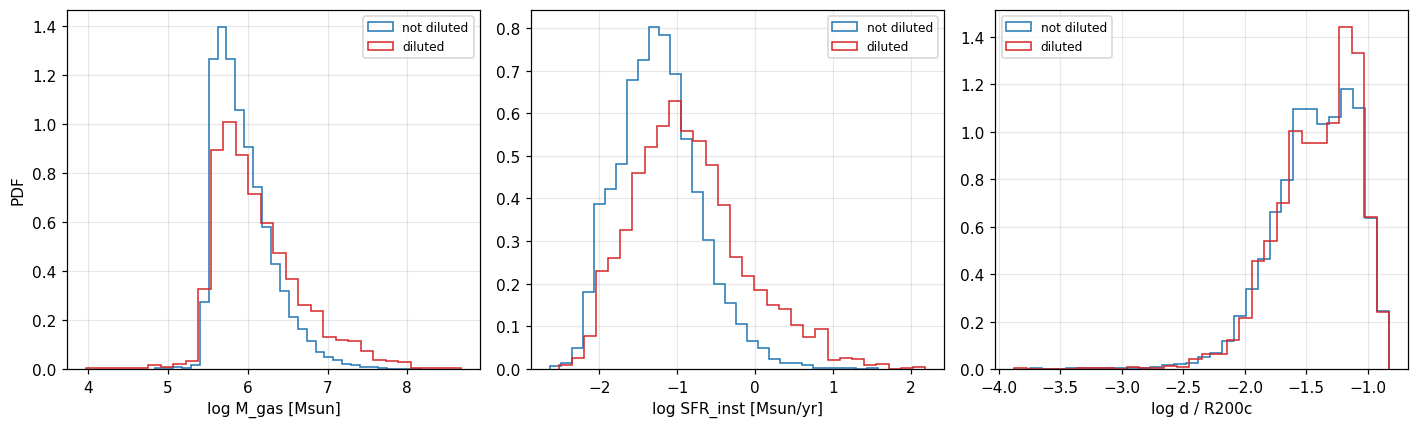

In [22]:
props = {"GasMass": "M_gas [Msun]", "sfr_inst": "SFR_inst [Msun/yr]", "alpha": "virial parameter",
         "Sigma_gas": "Sigma_gas [Msun/pc^2]", "x": "d / R200c", "R_eff_pc": "R_eff [pc]"}
f4 = sfc[sfc["res"] == 4]
print("4x: median properties, diluted vs not (star-forming clumps)")
display(f4.groupby("diluted")[list(props)].median().rename(columns=props).T.round(3))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["GasMass", "sfr_inst", "x"]):
    for flag, colr, lab in [(False, "C0", "not diluted"), (True, "C3", "diluted")]:
        v = f4.loc[f4["diluted"] == flag, col]
        ax.hist(np.log10(v[v > 0]), bins=30, histtype="step", density=True, color=colr, lw=1.5, label=lab)
    ax.set_xlabel("log " + props[col]); ax.legend(fontsize=8)
axes[0].set_ylabel("PDF")
plt.tight_layout(); plt.show()

## 6. Radial trend at fixed redshift

4× runs, **all matched clouds** (`clumps_all`), since this section is about radius and the galaxy boundary would cut it off at R_gal ≈ 0.15 R200c. Distance is `|CenterPosition|`, normalised by R₂₀₀c from the tree. Metallicity rises with time, so pooling redshifts would turn that time evolution into a fake radial trend; each curve below is one redshift bin.


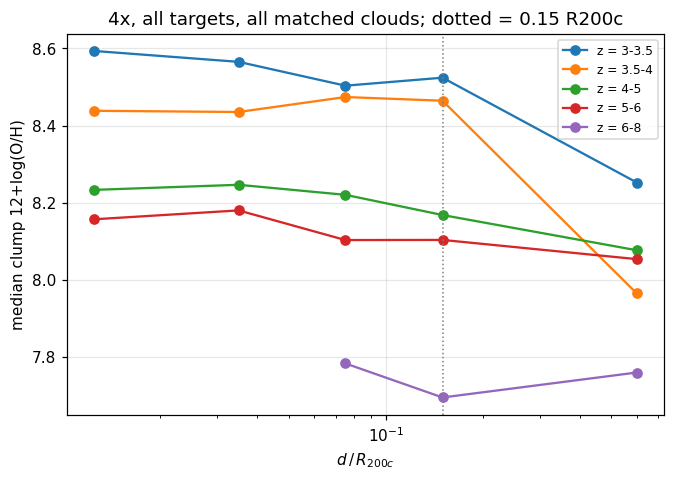

In [23]:
edges = [0.005, 0.02, 0.05, 0.1, 0.2, 1.0]
c4 = clumps_all[clumps_all["res"] == 4]
fig, ax = plt.subplots(figsize=(7, 4.5))
for lo, hi in [(3, 3.5), (3.5, 4), (4, 5), (5, 6), (6, 8)]:
    d = c4[c4["z"].between(lo, hi)]
    g = d.groupby(pd.cut(d["x"], edges), observed=True)["OH"]
    med, n = g.median(), g.size()
    keep_bins = n >= 20
    if keep_bins.sum() >= 2:
        ax.plot([iv.mid for iv in med.index[keep_bins]], med[keep_bins], "o-", label=f"z = {lo}-{hi}")
ax.set_xscale("log")
ax.set_xlabel(r"$d\,/\,R_{200c}$")
ax.set_ylabel("median clump 12+log(O/H)")
ax.axvline(0.15, color="0.5", ls=":", lw=1)
ax.set_title("4x, all targets, all matched clouds; dotted = 0.15 R200c")
ax.legend(fontsize=8)
plt.show()

## 7. What correlates with a clump's metallicity?

This replaces the earlier all-column correlation matrix and the `correlation_*.py` plots. Those pooled z = 15 → 3, so every correlation was mostly time evolution, and the top pairs were bookkeeping: `SFR_yso` is exactly `StellarMass/3000` (r = 1), each element tracks its own `_sfr` version, and the elements track each other.

Here the metallicity is measured relative to the median clump of the same snapshot, which removes time evolution and does not depend on any host definition. Spearman rank correlation is used so the many clumps with zero SFR or zero young stars are kept (as ties) rather than dropped by a log axis.


In [24]:
cols = {"GasMass": "gas mass", "StellarMass": "young-star mass (< 3 Myr)", "sfr_inst": "SFR_inst",
        "alpha": "virial parameter", "R_eff_pc": "effective radius", "Sigma_gas": "gas surface density",
        "n_H": "mean density", "x": "d / R200c"}
rows = []
for res in sorted(clumps["res"].unique()):
    d = clumps[multi & (clumps["res"] == res)]
    for col, lab in cols.items():
        r, p = spearmanr(d[col], d["dOH_vs_snapshot"])
        rows.append({"property": lab, "res": f"{res}x", "rho": r, "p": p})
t = pd.DataFrame(rows)
print("Spearman rho of clump O/H (relative to its snapshot's median clump) with each property")
t.pivot(index="property", columns="res", values="rho").round(3)

Spearman rho of clump O/H (relative to its snapshot's median clump) with each property


res,4x,8x
property,,
SFR_inst,-0.055,0.008
d / R200c,-0.097,-0.158
effective radius,-0.076,0.020
gas mass,-0.098,0.008
gas surface density,-0.048,-0.016
mean density,0.034,-0.023
virial parameter,0.010,0.119
young-star mass (< 3 Myr),-0.174,0.062


## 8. Resolution

Within-snapshot clump scatter needs no host, so it can be compared across every catalog. Four targets exist at both 4× and 8× (g10304, g33206, g37591, g5760), which gives a clean same-galaxy test of whether the clump–host offset and the clump scatter depend on resolution.


In [25]:
rows = []
for res in [4, 8, 16]:
    c = tz_gmc.load(res=res, variant="fiducial", resolved_only=True)
    c["OH"] = oh12(c["O_Fraction"], c["H_Fraction"])
    grp = c.groupby(["Run", "Snapshot", "HaloID"])["OH"]
    big = grp.transform("size") >= 5
    dev = (c["OH"] - grp.transform("median"))[big]
    rows.append({"resolution": f"{res}x", "clumps": int(big.sum()), "z range": "%.1f - %.1f" % (c["z"].min(), c["z"].max()),
                 "16th pct": dev.quantile(0.16), "84th pct": dev.quantile(0.84),
                 "% > 0.1 dex below median": 100 * (dev < -0.1).mean()})
pd.DataFrame(rows).set_index("resolution").round(3)

,clumps,z range,16th pct,84th pct,% > 0.1 dex below median
resolution,,,,,
4x,28819,3.0 - 15.1,-0.084,0.067,13.189
8x,27077,3.0 - 9.2,-0.104,0.077,16.715
16x,1443,3.1 - 3.5,-0.176,0.061,20.097


In [26]:
pairs = ["g10304", "g33206", "g37591", "g5760"]
rows = []
for t in pairs:
    for res in [4, 8]:
        run = f"{t}z{res}"
        s = snaps[snaps.index.get_level_values("Run") == run] if "Run" in snaps.index.names else snaps[snaps["Run"] == run]
        c = clumps[(clumps["Run"] == run) & multi]
        rows.append({"target": t, "res": f"{res}x", "snapshots": int(s["dOH_sfrw_out"].notna().sum()),
                     "median clump M_gas": clumps.loc[clumps["Run"] == run, "M_gas"].median(),
                     "headline offset, median": s["dOH_sfrw_out"].median(),
                     "offset vs all gas, median": s["dOH_all"].median(),
                     "clump scatter 16-84 width": c["dOH_vs_snapshot"].quantile(0.84) - c["dOH_vs_snapshot"].quantile(0.16)
                                                  if len(c) else np.nan})
pd.DataFrame(rows).set_index(["target", "res"]).round(3)

snapshots  median clump M_gas  headline offset, median  \
target res                                                           
g10304 4x          17          651860.500                    0.012   
       8x          34          125938.953                    0.087   
g33206 4x           6          600529.469                   -0.046   
       8x           9           91600.188                   -0.011   
g37591 4x           2          714296.344                    0.024   
       8x          26           92157.906                   -0.001   
g5760  4x          25          641938.875                    0.061   
       8x          57           96096.727                    0.110   

            offset vs all gas, median  clump scatter 16-84 width  
target res                                                        
g10304 4x                       0.029                      0.085  
       8x                       0.035                      0.161  
g33206 4x                       0.009                      0.117  
       8x                       0.005                      0.205  
g37591 4x                       0.001                        NaN  
       8x                      -0.007                      0.138  
g5760  4x                       0.029                      0.122  
       8x                       0.018                      0.149

## 9. Sensitivity of the headline to the analysis choices

The headline is Δ12+log(O/H) of star-forming clumps against the host's star-forming gas outside the clumps, per snapshot. Each row below changes one choice and reruns the whole comparison; the first row is the default. For each resolution: median over snapshots [16th, 84th] (number of snapshots), the range of per-run medians (runs with ≥ 5 snapshots), and the share of snapshots at or below the JWST-reported −0.1 dex.


In [27]:
variants = [
    ("default: inside R_gal, N >= 30, SFR-weighted clump O/H, median", dict(cl=clumps)),
    ("all matched clouds (no galaxy boundary)", dict(cl=clumps_all)),
    ("resolution cut N >= 50", dict(cl=clumps[clumps["Number_of_Particles"] >= 50])),
    ("resolution cut N >= 100", dict(cl=clumps[clumps["Number_of_Particles"] >= 100])),
    (">= 3 star-forming clumps per snapshot", dict(cl=clumps, min_sf=3)),
    (">= 10 star-forming clumps per snapshot", dict(cl=clumps, min_sf=10)),
    ("all clumps combined (SFR-weighted O and H)", dict(cl=clumps, stat="sfr_agg")),
    ("mass-weighted clump O/H", dict(cl=clumps, oh_col="OH")),
    ("star-forming = SFR_yso > 0 (3 Myr), mass-weighted O/H",
     dict(cl=clumps.assign(sf_yso=clumps["sfr_yso"] > 0), sf_col="sf_yso", oh_col="OH")),
    ("'outside clumps' defined up to 70% clump share", dict(cl=clumps, fmax=0.7)),
    ("'outside clumps' defined up to 97% clump share", dict(cl=clumps, fmax=0.97)),
]

sens, results = [], {}
for name, kw in variants:
    cl = kw.pop("cl")
    results[name] = build_snaps(cl, **kw)
# merger snapshots (clouds out-form the central even inside R_gal), dropped from the default
d0 = results[variants[0][0]]
results["default, without snapshots where clouds out-form the central"] = d0[~(d0["f_clump_SFR"] > 1.0001)]

for name, sn in results.items():
    row = {"variant": name}
    for res in [4, 8]:
        s = sn.loc[sn["res"] == res, "dOH_sfrw_out"].dropna()
        per_run = sn[sn["res"] == res].groupby(level="Run")["dOH_sfrw_out"].agg(["median", "count"])
        per_run = per_run[per_run["count"] >= 5]["median"]
        row[f"{res}x median [16, 84] (n)"] = ("%+.3f [%+.3f, %+.3f] (%d)" % (s.median(), s.quantile(.16), s.quantile(.84), len(s))
                                            if len(s) else "-")
        row[f"{res}x run medians"] = "%+.3f .. %+.3f" % (per_run.min(), per_run.max()) if len(per_run) else "-"
        row[f"{res}x % <= -0.1 dex"] = round(100 * (s <= -0.1).mean(), 1) if len(s) else np.nan
    sens.append(row)
pd.set_option("display.max_colwidth", 70)
sens = pd.DataFrame(sens).set_index("variant")
sens

,"4x median [16, 84] (n)",4x run medians,4x % <= -0.1 dex,"8x median [16, 84] (n)",8x run medians,8x % <= -0.1 dex
variant,,,,,,
"default: inside R_gal, N >= 30, SFR-weighted clump O/H, median","+0.026 [-0.021, +0.088] (236)",-0.046 .. +0.061,3.4,"+0.077 [-0.050, +0.194] (126)",-0.011 .. +0.110,7.1
all matched clouds (no galaxy boundary),"+0.022 [-0.025, +0.083] (250)",-0.058 .. +0.041,4.4,"+0.035 [-0.075, +0.192] (132)",-0.063 .. +0.097,10.6
resolution cut N >= 50,"+0.016 [-0.028, +0.076] (222)",-0.035 .. +0.047,3.6,"+0.071 [-0.052, +0.193] (121)",-0.040 .. +0.094,7.4
resolution cut N >= 100,"+0.002 [-0.045, +0.058] (188)",-0.033 .. +0.027,2.7,"+0.060 [-0.051, +0.144] (110)",-0.022 .. +0.099,5.5
>= 3 star-forming clumps per snapshot,"+0.021 [-0.014, +0.070] (171)",+0.003 .. +0.036,2.3,"+0.088 [-0.010, +0.195] (83)",+0.003 .. +0.123,1.2
>= 10 star-forming clumps per snapshot,"+0.016 [-0.008, +0.063] (112)",+0.010 .. +0.021,0.9,"+0.082 [+0.014, +0.170] (30)",+0.082 .. +0.082,0.0
all clumps combined (SFR-weighted O and H),"-0.001 [-0.089, +0.084] (236)",-0.101 .. +0.072,14.4,"+0.068 [-0.050, +0.202] (126)",-0.023 .. +0.118,7.1
mass-weighted clump O/H,"+0.048 [+0.000, +0.114] (236)",-0.029 .. +0.078,3.0,"+0.076 [-0.043, +0.193] (126)",-0.004 .. +0.118,7.9
"star-forming = SFR_yso > 0 (3 Myr), mass-weighted O/H","+0.051 [-0.008, +0.114] (267)",-0.017 .. +0.078,3.0,"+0.066 [-0.043, +0.205] (162)",+0.014 .. +0.136,8.0


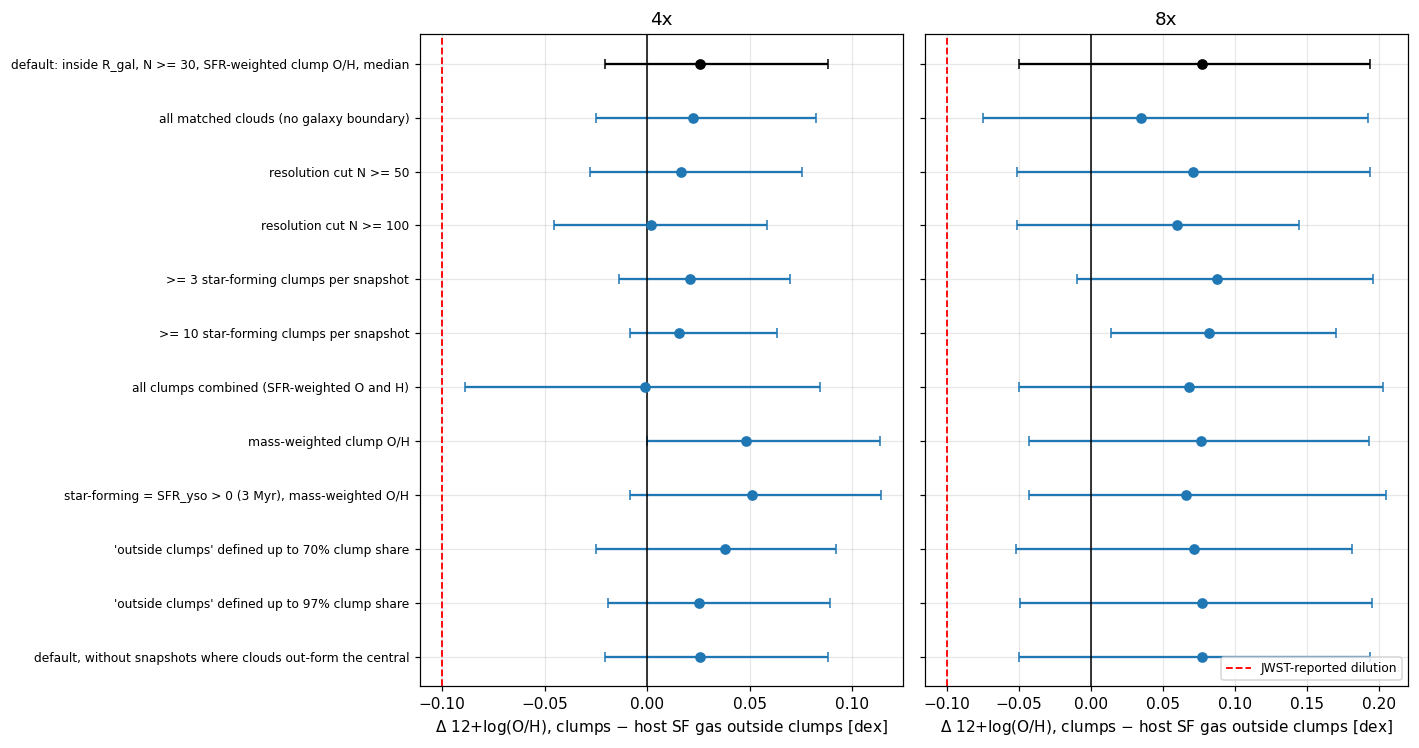

In [28]:
# The same, as a picture: median and 16th-84th percentile per variant
fig, axes = plt.subplots(1, 2, figsize=(13, 0.45 * len(results) + 1.5), sharey=True)
names = list(results)
for ax, res in zip(axes, [4, 8]):
    for k, name in enumerate(names):
        s = results[name].loc[results[name]["res"] == res, "dOH_sfrw_out"].dropna()
        if len(s):
            ax.errorbar(s.median(), k, xerr=[[s.median() - s.quantile(.16)], [s.quantile(.84) - s.median()]],
                        fmt="o", color="C0" if k else "k", capsize=3)
    ax.axvline(0, color="k", lw=1)
    ax.axvline(-0.1, color="r", ls="--", lw=1.2, label="JWST-reported dilution")
    ax.set_xlabel(r"$\Delta$ 12+log(O/H), clumps $-$ host SF gas outside clumps [dex]")
    ax.set_title(f"{res}x")
axes[0].set_yticks(range(len(names)))
axes[0].set_yticklabels(names, fontsize=8)
axes[0].invert_yaxis()
axes[1].legend(fontsize=8, loc="lower right")
plt.tight_layout()
plt.show()

### 9b. Why the SFR-weighted combination is lower: the brightest clumps

Combining clumps weighted by SFR gives a lower offset than the median clump. The reason: within a galaxy, the most star-forming clumps are the metal-poorest, and only in the massive hosts (g39, g205, g578, g1163). The trend holds at fixed cloud gas mass and is stronger in SFR-weighted than in mass-weighted O/H, i.e. inside a bright cloud the cells forming stars are less enriched than the cloud's gas on average.

Observations select the brightest clumps, so the table below compares them with the host: the single brightest clump per snapshot, and the top 10% by SFR in snapshots with ≥ 10 star-forming clumps. **Preliminary**: the strong signal comes from one galaxy (g39).


In [29]:
from scipy.stats import spearmanr

sf = clumps[clumps["star_forming"]].join(snaps[["OH_sfrw_out"]], on=["Run", "Snapshot"])
g = sf.groupby(["Run", "Snapshot"])
sf["dOH_snap"] = sf["OH_sfr"] - g["OH_sfr"].transform("median")     # vs the other clumps
sf["sfr_rank"] = g["sfr_inst"].rank(pct=True)
sf["n_sf"] = g["sfr_inst"].transform("size")
sf["dOH_host"] = sf["OH_sfr"] - sf["OH_sfrw_out"]                     # vs host SF gas outside clumps

rows = []
for run, d in sf.groupby("Run"):
    w = d[d["n_sf"] >= 5]
    h = d[d["OH_sfrw_out"].notna()]
    if len(h) == 0 or h["Snapshot"].nunique() < 5:
        continue
    bright = h.loc[h.groupby("Snapshot")["sfr_inst"].idxmax()]
    top = h[(h["sfr_rank"] > 0.9) & (h["n_sf"] >= 10)].groupby("Snapshot")["dOH_host"].median()
    rows.append({
        "run": run, "log M200c at z=3": np.log10(pd.read_csv(tz_gmc.host_tree_path(run[:-2] + "_" + run[-2:]))
                                                  ["phys_Group_Group_M_Crit200_Msun"].iloc[-1]),
        "rho(SFR, O/H vs other clumps)": spearmanr(w["sfr_inst"], w["dOH_snap"])[0] if len(w) >= 50 else np.nan,
        "all SF clumps vs host": h["dOH_host"].median(),
        "brightest clump vs host": bright["dOH_host"].median(),
        "% snapshots brightest <= -0.1": 100 * (bright["dOH_host"] <= -0.1).mean(),
        "top-10% vs host (per-snapshot median)": top.median() if len(top) else np.nan,
        "snapshots": h["Snapshot"].nunique()})
pd.DataFrame(rows).set_index("run").sort_values("log M200c at z=3", ascending=False).round(3)

,log M200c at z=3,"rho(SFR, O/H vs other clumps)",all SF clumps vs host,brightest clump vs host,% snapshots brightest <= -0.1,top-10% vs host (per-snapshot median),snapshots
run,,,,,,,
g39z4,12.558,-0.289,0.023,-0.218,81.081,-0.097,37
g205z4,12.125,-0.173,0.012,-0.031,29.412,-0.038,68
g578z4,11.838,-0.221,0.018,0.036,5.263,0.010,38
g1163z4,11.419,-0.119,0.019,0.024,11.628,-0.018,43
g5760z4,11.082,0.099,0.042,0.062,4.000,0.068,25
g5760z8,11.076,-0.008,0.077,0.122,5.263,0.100,57
g10304z8,10.821,0.001,0.109,0.097,17.647,0.181,34
g10304z4,10.778,0.047,-0.003,-0.004,5.882,-0.024,17
g33206z4,10.377,NaN,-0.053,-0.036,0.000,NaN,6


## 10. Robustness of the g39 bright-clump signal

Three quick tests of the result in §9b (g39's brightest clump sits ~0.2 dex below the host's star-forming gas):

- **A. Redshift**: does the offset hold at every epoch the catalog covers?
- **B. Galaxy boundary**: does it depend on where the galaxy is cut off?
- **C. Companion or in-situ**: is the brightest clump another galaxy falling in, or part of g39?

`brightest_per_snapshot()` is reusable for the tasks in section 11.


In [30]:
def brightest_per_snapshot(cl, run, sn=None):
    """The most star-forming clump of each snapshot of `run`, with its offset
    from the host's star-forming gas outside the clumps (column dOH)."""
    sn = build_snaps(cl) if sn is None else sn
    s = cl[cl["star_forming"] & (cl["Run"] == run)].join(sn[["OH_sfrw_out", "f_clump_SFR"]], on=["Run", "Snapshot"])
    s = s[s["OH_sfrw_out"].notna()]
    b = s.loc[s.groupby("Snapshot")["sfr_inst"].idxmax()].copy()
    b["dOH"] = b["OH_sfr"] - b["OH_sfrw_out"]
    return b


b39 = brightest_per_snapshot(clumps, "g39z4", snaps)

print("A. redshift (g39, brightest clump per snapshot)")
display(b39.groupby(pd.cut(b39["z"], [3, 3.5, 4, 6, 8, 16]), observed=True)["dOH"]
        .agg(snapshots="size", median="median", pct_le_m01=lambda s: 100 * (s <= -0.1).mean()).round(3))

print("B. galaxy boundary")
for lab, cl in [("default R_gal", clumps),
                ("0.5 x R_gal (inner galaxy)", clumps_all[clumps_all["d_center_kpc"] < 0.5 * clumps_all["R_gal"]]),
                ("no boundary", clumps_all)]:
    b = brightest_per_snapshot(cl, "g39z4")
    print("   %-28s median %+.3f dex, %3.0f%% of snapshots <= -0.1  (n=%d)"
          % (lab, b["dOH"].median(), 100 * (b["dOH"] <= -0.1).mean(), len(b)))

print("\nC. companion or in-situ?")
others = clumps[clumps["star_forming"] & (clumps["Run"] == "g39z4") & clumps["Snapshot"].isin(b39["Snapshot"])
                & ~clumps.index.isin(b39.index)]
print("   brightest clump: median d = %.2f kpc (%.2f R_gal), %.0f%% of the host SFR"
      % (b39["d_center_kpc"].median(), (b39["d_center_kpc"] / b39["R_gal"]).median(),
         100 * (b39["sfr_inst"] / b39["host_SFR"]).median()))
print("   SFR of other subhaloes in the group (1 - central/group): median %.3f"
      % (1 - b39["host_SFR"] / b39["group_SFR"]).median())
print("   gas mass: brightest %.1e vs other star-forming clumps %.1e Msun;  O/Fe %.2f vs %.2f"
      % (b39["GasMass"].median(), others["GasMass"].median(), b39["OFe"].median(), others["OFe"].median()))

A. redshift (g39, brightest clump per snapshot)


,snapshots,median,pct_le_m01
z,,,
"(3.0, 3.5]",27,-0.215,81.481
"(3.5, 4.0]",7,-0.259,100.000
"(8.0, 16.0]",3,-0.071,33.333


B. galaxy boundary


   default R_gal                median -0.218 dex,  81% of snapshots <= -0.1  (n=37)
   0.5 x R_gal (inner galaxy)   median -0.182 dex,  72% of snapshots <= -0.1  (n=36)


   no boundary                  median -0.209 dex,  72% of snapshots <= -0.1  (n=40)

C. companion or in-situ?
   brightest clump: median d = 1.74 kpc (0.17 R_gal), 13% of the host SFR
   SFR of other subhaloes in the group (1 - central/group): median 0.053
   gas mass: brightest 4.5e+07 vs other star-forming clumps 7.6e+05 Msun;  O/Fe 9.84 vs 9.35


**Result (2026-11-13).**
- **A.** The catalog covers g39 almost only at z = 3–4 (34 snapshots) plus 3 at z > 8. At z = 3–4 the brightest clump is −0.22 to −0.26 dex below the host, with 81–100% of snapshots ≤ −0.1 dex. Intermediate redshifts cannot be tested (not processed, §1b).
- **B.** Robust to the boundary: −0.18 (inner half), −0.22 (default), −0.21 dex (no boundary).
- **C.** In-situ, not a companion: the brightest clump sits at ~1.7 kpc (0.17 R_gal), and other subhaloes contribute only ~5% of the group's SFR. It is a **giant**: ~4.5×10⁷ Msun of gas, ~60× a typical cloud, the mass scale of JWST clumps. Its O/Fe is slightly higher than the other clumps'.

Still open: why the giant clumps are metal-poor (inflow? their position?), whether this is a halo-mass or a redshift effect, and whether it survives at the scale of JWST clumps. Those are the tasks below.


---
# 11. Tasks

Start by running the whole notebook from the top (Kernel → Restart & Run All), then work in the cells below. Everything you need already exists:

| object | what it is |
|---|---|
| `clumps` | resolved clouds inside the host galaxy (default sample); `clumps_all` has every matched cloud |
| `snaps` | one row per (run, snapshot): host apertures and clump-vs-host offsets, made by `build_snaps()` |
| `hosts[run]` | the host tree for each run, per snapshot |
| `brightest_per_snapshot(cl, run)` | most star-forming clump per snapshot, with its offset `dOH` |
| `oh12(xO, xH)` | 12 + log(O/H) from mass fractions |

**Ground rules** (each comes from a mistake already made once in this project — see `PROGRESS.md` §3):

1. Before any plot, print the **min / median / max** of every new quantity and ask whether the range is physically possible.
2. Metallicity is the sum of the C..Fe fractions (`Z_Zsun`, `OH`, `OH_sfr`), **never** `1 - H - He`.
3. `d_center_kpc` is already the distance from the host centre; do not subtract `GroupPos` again.
4. Clumps in one snapshot are not independent: summarise **per snapshot** first, then across snapshots.
5. Compare **at fixed redshift** (or redshift bins); otherwise time evolution looks like a trend.
6. Write what you find, with numbers, into `PROGRESS.md` (results section and the log).


## Task 1 — What is a "brightest clump"?

**Goal.** Describe the brightest clumps of g39 and g205 physically, and say how they differ from the other star-forming clumps in the same snapshots.

**Why.** They are ~60× more massive than a typical cloud and metal-poor relative to the host. Before explaining that, we need to know what kind of object they are: one giant cloud, a long filament, a cloud full of young stars?

**Steps.**
1. For g39 and g205, take `brightest_per_snapshot(clumps, run)` and the other star-forming clumps of the same snapshots.
2. Compare: `GasMass`, `R_eff_pc`, `Sigma_gas`, `alpha`, `M_star` (young stars), `d_center_kpc / R_gal`, `OFe`, `Number_of_Particles`.
3. Make one figure with a histogram per property (two colours: brightest vs others), log-scaled where it helps.

**Deliver.** A short table of medians and the figure; two or three sentences on what the brightest clumps are.


In [31]:
# Task 1 -- what is a brightest clump?
# TODO 1: brightest clumps of g39 and g205 (use brightest_per_snapshot)
# TODO 2: the other star-forming clumps in the same snapshots
# TODO 3: print min / median / max of each property for both groups (ground rule 1)
# TODO 4: histograms, brightest vs others


## Task 2 — Halo mass or redshift?

**Goal.** Find out whether the dilution of the brightest clump follows the host's halo mass or the redshift.

**Why.** The effect is strongest in g39 and g205, the two most massive hosts, and in g39 it is only measured at z = 3–4. Massive galaxies at low redshift are both, so the two are mixed up.

**Steps.**
1. For every run in `hosts` that has at least 5 usable snapshots, get `brightest_per_snapshot(clumps, run)`.
2. Attach the host's halo mass **at that snapshot**: read the tree with `pd.read_csv(tz_gmc.host_tree_path("g39_z4"))` and use `phys_Group_Group_M_Crit200_Msun` (not the z = 3 value).
3. Plot `dOH` against log M200c, coloured by redshift, with a line at −0.1 dex.
4. Repeat within one redshift bin (e.g. z = 3–4) so time evolution cannot drive the trend.

**Check.** Each run should contribute one point per snapshot, not one per clump.

**Deliver.** The figure and a sentence: is there a halo-mass threshold for dilution?


In [32]:
# Task 2 -- halo mass or redshift?
# TODO 1: loop over runs, collect brightest_per_snapshot(...) with the run name
# TODO 2: attach log10 M200c at each snapshot from the host tree
# TODO 3: print min / median / max of dOH and log M200c (ground rule 1)
# TODO 4: dOH vs log M200c coloured by z; then the same for 3 < z < 4 only


## Task 3 — Clump complexes at JWST scale

**Goal.** Group clouds into complexes on the scale of JWST clumps, and repeat the clump-vs-host comparison for complexes.

**Why.** JWST clumps are hundreds of pc across and ~10⁷–10⁸ Msun; a CloudPhinder cloud at 4× is ~30 pc and ~10⁶ Msun. Observed "clumps" are probably complexes of many clouds. The brightest giant clumps already reach this scale; do complexes built from ordinary clouds behave the same way?

**Steps.**
1. In each snapshot of a run, link clouds whose centres are closer than a linking length ℓ (try 200 pc and 500 pc). Hint: `scipy.spatial.cKDTree(pos).query_pairs(l)` gives the pairs; `scipy.sparse.csgraph.connected_components` turns them into groups.
2. For each complex: total gas mass, total `sfr_inst`, and SFR-weighted O and H (sum of `sfr_inst * O_Fraction_sfr` and `sfr_inst * H_Fraction_sfr` over its star-forming clouds), then `oh12(...)`.
3. Compare each complex with the host's star-forming gas outside the clumps (`snaps["OH_sfrw_out"]`): the median complex and the brightest complex per snapshot.
4. Do it for g39 and g205 first; then for all 4× runs.

**Check.** Complex masses should land around 10⁷–10⁸ Msun for ℓ = 500 pc; print the distribution before going on.

**Deliver.** For each ℓ: number of complexes, mass distribution, and the median/brightest offset per run.


In [33]:
# Task 3 -- clump complexes
from scipy.spatial import cKDTree
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# TODO 1: write label_complexes(c, l_kpc) for the clouds c of ONE snapshot -> array of complex labels
#         positions: c[["CenterPosition_x", "CenterPosition_y", "CenterPosition_z"]].to_numpy()  (kpc)
# TODO 2: aggregate per complex: gas mass, sfr_inst, SFR-weighted O and H -> oh12
# TODO 3: print the complex mass distribution for l = 0.2 and 0.5 kpc (ground rule 1)
# TODO 4: offsets vs snaps["OH_sfrw_out"]: median complex and brightest complex, per snapshot
